# <font color=RED> ROMPEBRECHAS — Entrega final </font>
### ¿Un cero en el registro de violencia escolar significa que no hubo violencia?

Este notebook contiene el proceso final del proyecto, desde las fuentes públicas del MINEDU hasta el veredicto. Solo
incluye los pasos que se usaron para llegar al resultado.

| Sección | Contenido |
|---|---|
| 1 – 4 | Carga y limpieza de cada fuente |
| 5 | Integración e indicadores |
| 6 | El problema en los datos (dos gráficos) |
| 7 | Matriz analítica |
| 8 | Método: perfiles de colegios con K-means y reglas de asociación (qué faltas van juntas) |
| 9 | Dónde están: mapa de los perfiles, zonas con DBSCAN y mapa para la UGEL |
| 10 | Veredicto, recomendaciones y limitaciones |

## <font color=yellow> Planteamiento del problema </font>

**Contexto.** En el Perú, cada colegio debe anotar los casos de violencia escolar en un *libro de registro de
incidencias* y reportarlos al **SíseVe**, el portal del MINEDU creado para ese fin. Con esa información, las UGEL y el
MINEDU deciden a qué colegios acompañar, capacitar o supervisar.

**Problema.** La mayoría de colegios de primaria reporta **cero casos**. Pero un cero puede significar dos cosas muy
distintas: que en el colegio no hubo violencia, o que el colegio no tiene cómo detectarla y registrarla (no tiene un
responsable de convivencia, el director no conoce los protocolos, etc.). Hoy los datos no permiten distinguir un caso
del otro.

**¿Por qué es un problema?** Si ese cero se lee como "aquí no pasa nada", los colegios con menos capacidad quedan fuera
de la atención justamente porque no registran: la violencia no se atiende y los estudiantes siguen expuestos. Además, la
violencia puede afectar la trayectoria escolar (que el estudiante repita de grado o deje el colegio), y eso tampoco se
estaría viendo.

**Objetivo.** Con datos públicos del MINEDU se construye una base en la que **cada fila es un colegio de primaria**, y con
ella se responden dos preguntas:

1.  ¿Qué características del colegio se asocian a que registre (o no) casos de violencia?
2.  ¿Los colegios que registran violencia tienen más estudiantes que repiten de grado o se retiran?

La meta es ayudar a la UGEL a **priorizar los colegios donde un cero dice poco**. Los datos no miden la violencia
ocurrida, así que no pueden confirmar qué colegio está libre de violencia, pero sí mostrar cuáles tienen menos capacidad
de registrarla.

*   **Usuarios:** los especialistas de convivencia escolar de las UGEL y DRE, y el equipo del MINEDU a cargo del SíseVe.
*   **Beneficiarios:** los estudiantes de primaria, en especial los de colegios donde hoy la violencia no se registra y,
    por lo tanto, no se atiende.

**Pregunta de análisis:** ¿Qué características institucionales se asocian a que un colegio de primaria del Perú registre
casos de violencia escolar, y se relaciona ese registro con la repetición y el retiro de sus estudiantes (2024-2025)?

**UNIDAD DE ANÁLISIS:** el servicio educativo de primaria (colegio), identificado por la llave `COD_MOD` + `ANEXO`.

| Fuente | Qué aporta | Granularidad original |
|---|---|---|
| Censo Educativo 2025, `Lineal_3AP_1` | Respuestas del director sobre convivencia escolar, tutoría y ESI | Un colegio |
| `Resultado_2025` (cédula 3BP, SIAGIE) | Repetición y retiro | Colegio × cuadro × situación (se pivoteó) |
| `Matricula_01` (cédula 3AP, cuadro C201) | Matrícula: denominador de las tasas | Colegio × turno (se sumaron los turnos) |
| `Padron_web` | Gestión, área, departamento y coordenadas | Un servicio de cualquier nivel (se filtró a primaria) |

**FUENTES:** Censo Educativo 2025 y Resultado del Ejercicio Educativo 2025
(https://escale.minedu.gob.pe/uee/-/document_library_display/GMv7/view/10632985) y Padrón de Instituciones Educativas
(https://escale.minedu.gob.pe/web/inicio/padron-de-iiee). Los `.dbf` originales se filtraron a primaria y se publicaron
en `.parquet` en Hugging Face: https://huggingface.co/datasets/themasterdrop/rompebrechas-violencia-escolar

**CÓMO SE ORGANIZA EL TRABAJO (CRISP-DM)**

| Fase de CRISP-DM | Qué se hace en este proyecto | Secciones |
|---|---|---|
| 1. Comprensión del problema | Pregunta, usuarios y unidad de análisis | Planteamiento |
| 2. Comprensión de los datos | Diagnóstico de calidad y análisis exploratorio | 1 – 4, 6 |
| 3. Preparación de los datos | Limpieza, integración, indicadores y matriz analítica | 1 – 5, 7 |
| 4. Modelado | K-means por atributos del colegio, reglas de asociación (Apriori) y DBSCAN espacial | 8, 9 |
| 5. Evaluación | Codo, silueta, Davies-Bouldin, estabilidad y comparación con otros métodos | 8 |
| 6. Despliegue | Mapa interactivo y lista priorizada de colegios para la UGEL | 9.3 |

## <font color=yellow> Preparación del entorno </font>

In [1]:
# apyori (reglas de asociación) no viene instalada en Colab
%pip install -q apyori

In [2]:
import io
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import fcluster, linkage
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from apyori import apriori  # se instaló en la celda anterior

pd.set_option("display.max_columns", 60)
sns.set_theme(style="ticks")

# Carpeta donde se guardan la base integrada, la matriz, las figuras y el mapa
SALIDAS = Path("salidas")
SALIDAS.mkdir(exist_ok=True)

In [3]:
# Las bases están publicadas en Hugging Face
URL_HF = "https://huggingface.co/datasets/themasterdrop/rompebrechas-violencia-escolar/resolve/main/"

def leer_de_hugging_face(nombre_archivo):
    with urllib.request.urlopen(URL_HF + nombre_archivo, timeout=120) as respuesta:
        return pd.read_parquet(io.BytesIO(respuesta.read()))

# COD_MOD tiene 7 caracteres y ANEXO 1. Si una fuente los trae como número y otra como texto,
# el merge falla en silencio y se pierden filas: todas las fuentes pasan por esta función.
LLAVE = ["COD_MOD", "ANEXO"]

def normalizar_llave(df):
    df = df.copy()
    df["COD_MOD"] = df["COD_MOD"].astype(str).str.strip().str.zfill(7)
    df["ANEXO"] = df["ANEXO"].astype(str).str.strip()
    return df

## <font color=yellow> 1. Censo Educativo 2025 — Lineal_3AP_1 </font>

### <font color=skyblue> 1.1 Carga y selección de variables </font>

De las 193 variables de la cédula 3AP se seleccionan las de identificación y las vinculadas a **convivencia escolar,
tutoría y educación sexual integral**, que son las que responden al problema.

In [4]:
df_censo = leer_de_hugging_face("censo_3ap_primaria.parquet")
df_censo.columns = [c.upper() for c in df_censo.columns]
print("Censo 3AP:", df_censo.shape)

# Variables de identificación
columnas_id = ["COD_MOD", "ANEXO", "CODLOCAL", "NROCED", "CEN_EDU", "DISTRITO",
               "LOCALIDAD", "CODGEO", "NIV_MOD", "GES_DEP"]

# Convivencia escolar y violencia (sección B de la cédula)
columnas_convivencia = [
    "P121B",        # cuenta con normas de convivencia escolar actualizadas
    "P122B",        # normas construidas con participación de estudiantes
    "P123B",        # cuenta con responsable de convivencia escolar
    "P124B",        # el colegio está afiliado al SíseVe
    "P124B_SI",     # si está afiliado: casos reportados hasta la fecha del Censo 2025
    "P124B_NO",     # si no está afiliado: razón de la no afiliación
    "P125B",        # cuenta con libro de registro de incidencias (Ley 29719)
    "P126B",        # en 2024 se hizo uso del libro de registro de incidencias
    "P126B_SI_1",   # si lo usó: cuántas incidencias se registraron en 2024
    "P127B",        # el director consulta el RNSSC para verificar al personal
    "P128B",        # el director conoce los protocolos de atención de violencia
    "P129B",        # sabe que los hechos deben reportarse también a la UGEL
]

# Familias, ESI, organización y tutoría
columnas_tutoria = [
    "P114A",        # realiza actividades dirigidas a familias (filtro de P116A)
    "P116A",        # actividad con familias con eje en Educación Sexual Integral
    "P121A",        # criterio de distribución de estudiantes en secciones
    "P122A",        # acciones para atender interrupción de estudios
    "P103B",        # cuenta con plan de tutoría y convivencia (Plan TOECE)
    "P105B",        # el plan TOECE incluye actividades de convivencia y violencia
    "P106B",        # implementó al menos 3 actividades de convivencia del plan TOECE
]

df_censo_final = normalizar_llave(df_censo[columnas_id + columnas_convivencia + columnas_tutoria])
print("Variables seleccionadas:", df_censo_final.shape)
print("IDs repetidos (COD_MOD + ANEXO):", df_censo_final.duplicated(subset=LLAVE).sum())

Censo 3AP: (37354, 193)
Variables seleccionadas: (37354, 29)
IDs repetidos (COD_MOD + ANEXO): 0


### <font color=skyblue> 1.2 Faltantes y estandarización </font>

En esta fuente los faltantes **no vienen como `NaN`**: vienen como **cadena vacía**, porque el `.dbf` guarda todo como
texto de ancho fijo. Por eso se cuentan los dos casos.

In [5]:
vacio_censo = df_censo_final.isna() | (df_censo_final.astype(str).apply(lambda s: s.str.strip()) == "")
faltantes_censo = pd.DataFrame({"faltantes": vacio_censo.sum(), "%": (vacio_censo.mean() * 100).round(1)})
display(faltantes_censo[faltantes_censo["faltantes"] > 0].sort_values("faltantes", ascending=False))

,faltantes,%
P126B_SI_1,32721,87.6
P124B_NO,30698,82.2
P106B,10680,28.6
P116A,7714,20.7
P124B_SI,6591,17.6
P126B,5875,15.7
P105B,5828,15.6
P122B,2150,5.8
LOCALIDAD,1158,3.1
P121B,40,0.1


In [6]:
# Variables SI/NO: quitar espacios y unificar mayúsculas. El vacío pasa a NaN
# porque "no respondió" no es lo mismo que "NO".
columnas_si_no = ["P121B", "P122B", "P123B", "P124B", "P125B", "P126B",
                  "P127B", "P128B", "P129B", "P116A", "P122A",
                  "P114A", "P103B", "P105B", "P106B"]

for col in columnas_si_no:
    df_censo_final[col] = (df_censo_final[col].astype(str).str.strip().str.upper()
                           .replace({"": np.nan, "NAN": np.nan, "NONE": np.nan}))

for col in ["DISTRITO", "LOCALIDAD", "CEN_EDU"]:
    df_censo_final[col] = df_censo_final[col].astype(str).str.strip().str.title()

df_censo_final["P124B_SI"] = pd.to_numeric(df_censo_final["P124B_SI"], errors="coerce")
df_censo_final["P126B_SI_1"] = pd.to_numeric(df_censo_final["P126B_SI_1"], errors="coerce")

### <font color=skyblue> 1.3 Variables de violencia escolar: preguntas condicionadas </font>

`P124B_SI` y `P126B_SI_1` solo se llenan si la respuesta a la pregunta filtro (`P124B`, `P126B`) fue *Sí*. Por eso un
vacío puede significar tres cosas distintas:

| Respuesta filtro | Qué significa el vacío | Cómo se trata |
|---|---|---|
| `SI` | El colegio sí registró, pero no anotó el número | Se imputa **0** (son 2 y 4 casos) |
| `NO` | El colegio no está afiliado / no usó el libro | Es un **0 estructural**, no un faltante |
| vacío | El director no respondió la pregunta filtro | Se deja como **NaN** |

Imputar la mediana asignaría incidencias a colegios que declararon no haber registrado ninguna.

In [7]:
# Casos reportados al SíseVe (hasta la fecha del Censo 2025)
df_censo_final["casos_siseve"] = np.where(
    df_censo_final["P124B"] == "SI", df_censo_final["P124B_SI"].fillna(0),
    np.where(df_censo_final["P124B"] == "NO", 0, np.nan))

# Incidencias registradas en el libro de incidencias durante 2024
df_censo_final["incidencias_libro"] = np.where(
    df_censo_final["P126B"] == "SI", df_censo_final["P126B_SI_1"].fillna(0),
    np.where(df_censo_final["P126B"] == "NO", 0, np.nan))

print("casos_siseve      -> sin dato:", df_censo_final["casos_siseve"].isna().sum())
print("incidencias_libro -> sin dato:", df_censo_final["incidencias_libro"].isna().sum())

# ¿Quiénes no tienen dato de incidencias? P126B solo corresponde si el colegio tiene libro (P125B)
display(pd.crosstab(df_censo_final["P125B"].fillna("vacío"), df_censo_final["P126B"].fillna("vacío"),
                    rownames=["P125B (tiene libro)"], colnames=["P126B (usó el libro en 2024)"]))

casos_siseve      -> sin dato: 34
incidencias_libro -> sin dato: 5875


P126B (usó el libro en 2024),NO,SI,vacío
P125B (tiene libro),,,
NO,396,22,5851
SI,26656,4379,10
vacío,19,7,14


De los 5,875 colegios sin dato de incidencias, **5,851 no tienen libro** (`P125B` = NO): la pregunta no les
correspondía. No es falta de respuesta: **sin libro no hay dónde registrar**. Por eso estos colegios no se imputan, sino
que forman un **grupo propio (sin libro)**: es justamente el *colegio sin capacidad de registro* que el problema busca
distinguir. El grupo se define con `P125B` = NO (**6,269 colegios**), porque otros 418 colegios sin libro sí
respondieron `P126B`.

**Otras preguntas condicionadas.** Según el diccionario, estas solo corresponden si la pregunta filtro es *Sí*; si el
filtro es NO, el vacío es un **0 estructural (NO)**:

| Pregunta | Depende de |
|---|---|
| `P116A` ESI con familias | `P114A` actividades con familias |
| `P105B` plan TOECE con actividades de convivencia | `P103B` tiene plan TOECE |
| `P106B` implementó 3+ actividades del plan TOECE | `P105B` |
| `P122B` normas construidas con estudiantes | `P121B` tiene normas de convivencia |

In [8]:
# El orden importa: P106B depende de P105B, que se completa antes.
condicionadas = {"P116A": "P114A", "P105B": "P103B", "P106B": "P105B", "P122B": "P121B"}
for pregunta, filtro in condicionadas.items():
    antes = df_censo_final[pregunta].isna().sum()
    sin_filtro = df_censo_final[filtro].eq("NO") & df_censo_final[pregunta].isna()
    df_censo_final.loc[sin_filtro, pregunta] = "NO"
    print(f"{pregunta} (depende de {filtro}): vacíos {antes:,} -> {df_censo_final[pregunta].isna().sum():,}")

P116A (depende de P114A): vacíos 7,714 -> 8
P105B (depende de P103B): vacíos 5,828 -> 45
P106B (depende de P105B): vacíos 10,680 -> 41
P122B (depende de P121B): vacíos 2,150 -> 22


### <font color=skyblue> 1.4 Valores fuera de rango </font>

El año escolar tiene unos 190 días lectivos. Más de 365 incidencias al año (más de una por día) es implausible y
probablemente un error de digitación. No se usa la regla del IQR: más del 85 % de los colegios registra cero, así que el
IQR vale 0 y marcaría como atípico a **cualquier colegio que registre algo**.

In [9]:
UMBRAL = 365
for col in ["casos_siseve", "incidencias_libro"]:
    fuera = df_censo_final[col] > UMBRAL
    print(f"{col}: {fuera.sum()} registros por encima de {UMBRAL}")
    df_censo_final.loc[fuera, col] = np.nan    # pocos casos y sin regla para corregirlos: NaN

display(df_censo_final[["casos_siseve", "incidencias_libro"]].describe().round(2))

casos_siseve: 0 registros por encima de 365
incidencias_libro: 2 registros por encima de 365


,casos_siseve,incidencias_libro
count,37320.00,31477.00
mean,0.18,0.55
std,1.15,3.67
min,0.00,0.00
25%,0.00,0.00
50%,0.00,0.00
75%,0.00,0.00
max,99.00,230.00


## <font color=yellow> 2. Resultado del Ejercicio Educativo 2025 </font>

El archivo `Resultado_2025.dbf` (ESCALE, fuente SIAGIE) viene en **formato largo**: cada fila es colegio × cuadro ×
situación, y las columnas `D01` a `D12` son grado × sexo. Antes de publicarlo en Hugging Face se filtró la cédula `3BP`
(primaria) y se pivoteó a una fila por colegio:

```python
res = pd.read_csv("res3bp.csv", dtype=str)     # Resultado_2025.dbf filtrado a NROCED == "3BP"
D = [f"D{i:02d}" for i in range(1, 13)]        # 1er a 6to grado x (Hombre, Mujer)
res["TOTAL"] = res[D].astype(int).sum(axis=1)
# C101 = situación final, C102 = motivo del retiro, C201 = recuperación
c101 = res[res["CUADRO"] == "C101"].pivot_table(
    index=["COD_MOD", "ANEXO"], columns="TIPDATO", values="TOTAL", aggfunc="sum", fill_value=0)
```

In [10]:
df_resultado = normalizar_llave(leer_de_hugging_face("resultado_primaria_2025.parquet"))
print("Resultado del Ejercicio Educativo (Primaria):", df_resultado.shape)

# Chequeos de calidad
situaciones = ["res_promovido", "res_requiere_recup", "res_permanece_grado",
               "res_posterga_eval", "res_retirado", "res_fallecido"]
print("Faltantes:", int(df_resultado.isna().sum().sum()))
print("IDs repetidos (COD_MOD + ANEXO):", df_resultado.duplicated(subset=LLAVE).sum())
print("Colegios donde la suma de situaciones no cuadra con res_evaluados:",
      (df_resultado[situaciones].sum(axis=1) != df_resultado["res_evaluados"]).sum())
print("Colegios con res_evaluados = 0:", (df_resultado["res_evaluados"] == 0).sum())

# Motivos de retiro
motivos = [c for c in df_resultado.columns if c.startswith("motret_") and c != "motret_total"]
display(pd.DataFrame({
    "estudiantes": df_resultado[motivos].sum().astype(int),
    "colegios con al menos un caso": (df_resultado[motivos] > 0).sum(),
}).sort_values("estudiantes", ascending=False))

Resultado del Ejercicio Educativo (Primaria): (38036, 41)
Faltantes: 0
IDs repetidos (COD_MOD + ANEXO): 0
Colegios donde la suma de situaciones no cuadra con res_evaluados: 0
Colegios con res_evaluados = 0: 0


,estudiantes,colegios con al menos un caso
motret_otro,10898,3584
motret_enfermedad,771,484
motret_economica,766,362
motret_labores_agricolas,142,67
motret_trabajo_infantil,14,12
motret_violencia,6,5
motret_adiccion,5,5


El motivo *violencia* aparece en apenas 5 colegios de todo el país: **no se usa**. Las variables de resultado que sí se
usan son la **repetición** y el **retiro**. Según el diccionario, la repetición tiene dos partes: quienes **permanecen en
el grado** (cuadro C101) y quienes, tras **requerir recuperación pedagógica**, terminan permaneciendo en el grado
(cuadro C201). Se suman las dos (sección 5.4).

## <font color=yellow> 3. Matrícula 2025 </font>

La matrícula es el **denominador**: sin ella, 5 incidencias en un colegio de 30 estudiantes y 5 en uno de 800 se ven
iguales. El cuadro C201 trae una fila por turno; antes de publicarlo se sumaron los turnos de cada colegio.

In [11]:
df_matricula = normalizar_llave(leer_de_hugging_face("matricula_primaria_2025.parquet"))
print("Matrícula (Primaria):", df_matricula.shape)

grados = [f"mat_g{i}" for i in range(1, 7)]
print("IDs repetidos (COD_MOD + ANEXO):", df_matricula.duplicated(subset=LLAVE).sum())
print("Colegios con matrícula total = 0:", (df_matricula["mat_total"] == 0).sum())
print("Descuadres entre grados y total:", (df_matricula[grados].sum(axis=1) != df_matricula["mat_total"]).sum())

# Atípicos por IQR: aquí sí funciona, porque la matrícula no se concentra en cero
q1, q3 = df_matricula["mat_total"].quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
print(f"Límite IQR: {limite:.0f} estudiantes -> {(df_matricula['mat_total'] > limite).sum()} colegios "
      f"(máximo: {df_matricula['mat_total'].max()})")

# Un colegio con matrícula 0 no puede servir de denominador
df_matricula["mat_total"] = df_matricula["mat_total"].replace(0, np.nan)

Matrícula (Primaria): (38338, 32)
IDs repetidos (COD_MOD + ANEXO): 0
Colegios con matrícula total = 0: 0
Descuadres entre grados y total: 0
Límite IQR: 219 estudiantes -> 4508 colegios (máximo: 2234)


Los colegios que marca el IQR son colegios grandes reales (la matrícula cuadra con la suma de grados): **se conservan**.
Su asimetría se corrige con el logaritmo en la matriz analítica (sección 7).

## <font color=yellow> 4. Padrón de Instituciones Educativas </font>

El padrón aporta la gestión, el área, el departamento y las coordenadas. Contiene **todos** los niveles educativos, así
que se filtra a primaria antes de integrar.

In [12]:
padron = normalizar_llave(leer_de_hugging_face("padron_iiee.parquet"))
print("Padrón de IIEE:", padron.shape)

# Tipos de dato
padron["NLAT_IE"] = pd.to_numeric(padron["NLAT_IE"], errors="coerce")
padron["NLONG_IE"] = pd.to_numeric(padron["NLONG_IE"], errors="coerce")
padron["FECHAREG"] = pd.to_datetime(padron["FECHAREG"], errors="coerce", dayfirst=True)
for col, ancho in [("CODLOCAL", 6), ("CODGEO", 6), ("CODOOII", 6)]:
    padron[col] = padron[col].astype(str).str.strip().str.zfill(ancho)

# Texto: quitar espacios, unificar mayúsculas y tildes
for col in ["D_NIV_MOD", "D_FORMA", "D_TIPSSEXO", "D_GESTION", "D_GES_DEP", "DAREACENSO", "D_ESTADO", "D_COD_TUR"]:
    padron[col] = padron[col].astype(str).str.strip()
for col in ["D_DPTO", "D_PROV", "D_DIST", "D_REGION", "D_DREUGEL"]:
    padron[col] = padron[col].astype(str).str.strip().str.upper()
for col in ["D_REGION", "D_DREUGEL"]:
    padron[col] = padron[col].str.normalize("NFKD").str.encode("ascii", errors="ignore").str.decode("utf-8")
# GRE y DRE son la misma entidad con distinta denominación regional
padron["D_REGION"] = padron["D_REGION"].replace({"GRE AREQUIPA": "DRE AREQUIPA", "GRE LA LIBERTAD": "DRE LA LIBERTAD",
                                                 "GRE LAMBAYEQUE": "DRE LAMBAYEQUE"})

Padrón de IIEE: (180792, 45)


In [13]:
# Coordenadas (0, 0) = sin georreferenciar; fuera del Perú = error
sin_coord = (padron["NLAT_IE"] == 0) & (padron["NLONG_IE"] == 0)
fuera_peru = ((padron["NLAT_IE"] < -18.4) | (padron["NLAT_IE"] > 0) |
              (padron["NLONG_IE"] < -81.4) | (padron["NLONG_IE"] > -68.6))
padron.loc[sin_coord | fuera_peru, ["NLAT_IE", "NLONG_IE"]] = np.nan
padron.loc[padron["FECHAREG"] > pd.Timestamp("today"), "FECHAREG"] = pd.NaT

# Las coordenadas que faltan se imputan con la mediana del distrito (CODGEO)
mediana_distrito = padron.groupby("CODGEO")[["NLAT_IE", "NLONG_IE"]].transform("median")
padron["coord_imputada"] = padron["NLAT_IE"].isna() & mediana_distrito["NLAT_IE"].notna()
padron[["NLAT_IE", "NLONG_IE"]] = padron[["NLAT_IE", "NLONG_IE"]].fillna(mediana_distrito)
print("Coordenadas imputadas con la mediana distrital:", int(padron["coord_imputada"].sum()))
print("IIEE que siguen sin coordenadas:", int(padron["NLAT_IE"].isna().sum()))

# Filtrar a primaria y quedarse con las columnas útiles
columnas_padron = ["COD_MOD", "ANEXO", "CODLOCAL", "CEN_EDU", "D_NIV_MOD", "D_GESTION",
                   "D_GES_DEP", "D_TIPSSEXO", "DAREACENSO", "CODGEO", "D_DPTO", "D_PROV",
                   "D_DIST", "D_REGION", "D_DREUGEL", "NLAT_IE", "NLONG_IE", "D_ESTADO", "coord_imputada"]
padron_limpio = (padron[padron["D_NIV_MOD"] == "Primaria"]
                 .drop_duplicates(subset=LLAVE)[columnas_padron])
print("Padrón de primaria:", padron_limpio.shape)

Coordenadas imputadas con la mediana distrital: 1302
IIEE que siguen sin coordenadas: 0
Padrón de primaria: (48061, 19)


## <font color=yellow> 5. Integración de datos </font>

Las cuatro fuentes están a la misma granularidad (un colegio por fila) y comparten la llave. El orden y el tipo de cruce
importan:

```
                 1 : 1
  PADRÓN primaria ─────── CENSO 3AP  ──(inner)──►  BASE ESCOLAR
                                                      │
                                     1 : 0..1 (left)  ├──── MATRÍCULA   (turnos sumados)
                                     1 : 0..1 (left)  └──── RESULTADO   (pivoteado)
```

1.  **Censo + Padrón → `inner`.** Un colegio sin respuestas del censo o sin datos del padrón no es analizable.
2.  **+ Matrícula → `left`.** Se adjunta a todos los colegios por separado, para que ninguno pierda su denominador.
3.  **+ Resultado → `left`.** Los colegios sin resultado quedan con NaN en repetición y retiro.

Cada `merge` usa `validate="one_to_one"`: si una llave estuviera repetida, pandas detiene el proceso en lugar de
duplicar filas en silencio.

In [14]:
base_escolar = pd.merge(df_censo_final, padron_limpio, on=LLAVE, how="inner",
                        suffixes=("_censo", "_padron"), validate="one_to_one")

# Las columnas de contexto que repiten matrícula y resultado ya vienen del censo y del padrón
contexto_matricula = ["NIV_MOD", "GES_DEP", "AREA_CENSO", "CODGEO", "CODOOII", "CODLOCAL"]
contexto_resultado = ["NIV_MOD", "GES_DEP", "AREA_CENSO", "CODGEO", "CODOOII", "FUENTE"]

base_final = (base_escolar
              .merge(df_matricula.drop(columns=contexto_matricula), on=LLAVE, how="left",
                     indicator="cruce_matricula", validate="one_to_one")
              .merge(df_resultado.drop(columns=contexto_resultado), on=LLAVE, how="left",
                     indicator="cruce_resultado", validate="one_to_one"))

padron_sin_censo = padron_limpio[~padron_limpio.set_index(LLAVE).index.isin(base_escolar.set_index(LLAVE).index)]

display(pd.DataFrame([
    ["Colegios del censo 3AP", len(df_censo_final)],
    ["Colegios del censo sin pareja en el padrón", len(df_censo_final) - len(base_escolar)],
    ["Colegios del padrón de primaria sin cédula 3AP", len(padron_sin_censo)],
    ["   de ellos, inactivos en el padrón", (padron_sin_censo["D_ESTADO"] == "Inactivo").sum()],
    ["Colegios de la base sin matrícula", (base_final["cruce_matricula"] == "left_only").sum()],
    ["Colegios de la base sin resultado del ejercicio", (base_final["cruce_resultado"] == "left_only").sum()],
    ["IDs repetidos en la base final", base_final.duplicated(subset=LLAVE).sum()],
    ["Base final (colegios)", len(base_final)],
], columns=["Verificación", "Colegios"]))

,Verificación,Colegios
0,Colegios del censo 3AP,37354
1,Colegios del censo sin pareja en el padrón,0
2,Colegios del padrón de primaria sin cédula 3AP,10707
3,"de ellos, inactivos en el padrón",9055
4,Colegios de la base sin matrícula,0
5,Colegios de la base sin resultado del ejercicio,122
6,IDs repetidos en la base final,0
7,Base final (colegios),37354


*   Todos los colegios del censo encuentran pareja en el padrón. Los 10,707 colegios del padrón sin cédula 3AP son en su
    mayoría inactivos (85 %) y se excluyen porque no tienen ninguna variable de convivencia.
*   Todos los colegios tienen matrícula. Los 122 sin resultado del ejercicio (casi todos privados) se conservan: solo
    quedan fuera de los cálculos de repetición y retiro.
*   Ningún `merge` duplicó filas: **37,354 colegios, uno por fila**.

### <font color=skyblue> 5.1 Construcción de indicadores </font>

*   **Coherencia.** Un colegio no puede registrar más incidencias que estudiantes matriculados: esos casos se anulan.
*   **Tamaño mínimo.** En un colegio con 5 estudiantes una incidencia da una tasa de 20 por cada 100. Las tasas se
    calculan solo con al menos 10 estudiantes (`MIN_MATRICULA`); para la repetición se exigen 20 (`MIN_EVALUADOS`).
*   **Repetición y retiro.** Se dividen entre la matrícula final (`res_evaluados`). Repitentes = permanece en el grado
    (C101) + permanece tras la recuperación pedagógica (C201).
*   **Índice de gestión de la convivencia (0 a 3).** Un punto por cada instrumento: responsable de convivencia
    (`P123B`), director que conoce los protocolos (`P128B`) y que sabe que debe reportar a la UGEL (`P129B`). **No incluye
    el libro** (`P125B`): el libro es con lo que se mide el registro, e incluirlo haría circular el análisis.

In [15]:
# Resguardo 1: casos imposibles respecto a la matrícula
for col in ["incidencias_libro", "casos_siseve"]:
    incoherentes = base_final[col] > base_final["mat_total"]
    print(f"{col}: {int(incoherentes.sum())} colegios con más casos que estudiantes -> NaN")
    base_final.loc[incoherentes, col] = np.nan

# Resguardo 2: tamaños mínimos
MIN_MATRICULA = 10
MIN_EVALUADOS = 20
matricula = base_final["mat_total"].where(base_final["mat_total"] >= MIN_MATRICULA)

# Violencia escolar registrada (por cada 100 estudiantes)
base_final["tasa_incidencias_100"] = (base_final["incidencias_libro"] / matricula * 100).round(3)
base_final["tasa_casos_siseve_100"] = (base_final["casos_siseve"] / matricula * 100).round(3)

# Trayectoria escolar
base_final["repitentes"] = base_final["res_permanece_grado"] + base_final["recup_permanece_grado"]
evaluados = base_final["res_evaluados"].replace(0, np.nan)
base_final["tasa_repeticion"] = (base_final["repitentes"] / evaluados).round(4)
base_final["tasa_retiro"] = (base_final["res_retirado"] / evaluados).round(4)

# Índice de gestión de la convivencia (NaN si el director no respondió alguno de los tres)
gestion_convivencia = ["P123B", "P128B", "P129B"]
base_final["indice_convivencia"] = (
    sum((base_final[c] == "SI").astype(int) for c in gestion_convivencia)
    .where(base_final[gestion_convivencia].notna().all(axis=1))
    .astype("Int64"))

# Tamaño del colegio (reglas de negocio), para describir los faltantes
base_final["tam_colegio"] = pd.cut(base_final["mat_total"], bins=[0, 30, 100, 300, 100000],
                                   labels=["Muy pequeño (1-30)", "Pequeño (31-100)", "Mediano (101-300)", "Grande (300+)"])

display(base_final[["mat_total", "incidencias_libro", "tasa_incidencias_100", "tasa_repeticion",
                    "tasa_retiro", "indice_convivencia"]].describe().round(3))

incidencias_libro: 24 colegios con más casos que estudiantes -> NaN
casos_siseve: 14 colegios con más casos que estudiantes -> NaN


,mat_total,incidencias_libro,tasa_incidencias_100,tasa_repeticion,tasa_retiro,indice_convivencia
count,37354.000,31453.000,25587.000,37232.000,37232.000,37303.0
mean,96.928,0.516,0.661,0.019,0.004,2.631
std,171.197,3.091,3.297,0.051,0.024,0.729
min,1.000,0.000,0.000,0.000,0.000,0.0
25%,12.000,0.000,0.000,0.000,0.000,3.0
50%,32.000,0.000,0.000,0.000,0.000,3.0
75%,96.000,0.000,0.000,0.012,0.000,3.0
max,2234.000,230.000,100.000,1.000,1.000,3.0


### <font color=skyblue> 5.2 ¿Los faltantes de incidencias son aleatorios? </font>

In [16]:
base_final["sin_dato_incidencias"] = base_final["incidencias_libro"].isna()

sin_dato = pd.concat([
    base_final.groupby(var, observed=True)["sin_dato_incidencias"].mean().mul(100)
    .rename_axis("categoría").reset_index(name="% sin dato").assign(variable=nombre)
    for var, nombre in [("tam_colegio", "Tamaño"), ("DAREACENSO", "Área"), ("D_GESTION", "Gestión")]
])
display(sin_dato[["variable", "categoría", "% sin dato"]].round(1))

print("Departamentos con más colegios sin dato (%):")
display(base_final.groupby("D_DPTO")["sin_dato_incidencias"].mean().mul(100)
        .sort_values(ascending=False).head(5).round(1))

,variable,categoría,% sin dato
0,Tamaño,Muy pequeño (1-30),20.9
1,Tamaño,Pequeño (31-100),14.4
2,Tamaño,Mediano (101-300),9.0
3,Tamaño,Grande (300+),4.0
0,Área,Rural,18.6
1,Área,Urbana,10.2
0,Gestión,Privada,13.9
1,Gestión,Pública de gestión directa,16.4
2,Gestión,Pública de gestión privada,12.4


Departamentos con más colegios sin dato (%):


D_DPTO
LORETO           47.0
UCAYALI          36.3
MADRE DE DIOS    22.9
AMAZONAS         21.6
PUNO             19.2
Name: sin_dato_incidencias, dtype: float64

**No es aleatorio:** casi todos los colegios sin dato son colegios **sin libro**, y se concentran en colegios pequeños,
rurales y amazónicos (Loreto 47 %, Ucayali 36 %). No se imputan: un colegio sin libro no tiene un número de incidencias
que imputar. Se cuentan aparte como **grupo sin capacidad de registro**.

In [17]:
# Base integrada (una fila por colegio), para partir de aquí sin volver a limpiar las fuentes
base_final.drop(columns=["cruce_matricula", "cruce_resultado"]).to_parquet(SALIDAS / "base_integrada.parquet", index=False)
print("Base integrada guardada:", base_final.shape, "->", SALIDAS / "base_integrada.parquet")

Base integrada guardada: (37354, 113) -> salidas\base_integrada.parquet


### <font color=skyblue> 5.3 Resumen de decisiones de limpieza </font>

| Fuente | Decisión | Por qué |
|---|---|---|
| Censo | Cadena vacía → NaN en las preguntas SI/NO | "No respondió" no es lo mismo que "NO" |
| Censo | `P124B_SI` y `P126B_SI_1`: 0 si el filtro es NO (o SI sin número); NaN si no respondió el filtro | Imputar la mediana asignaría casos a colegios que declararon cero |
| Censo | Colegios sin libro (`P125B` = NO) como grupo propio | Sin libro no se puede registrar: no es falta de respuesta |
| Censo | `P116A`, `P105B`, `P106B`, `P122B`: NO si la pregunta filtro es NO | Son preguntas condicionadas (0 estructural) |
| Censo | Incidencias > 365 → NaN, con regla de negocio y no con el IQR | El IQR vale 0 y marcaría a todo colegio que registra |
| Resultado | Filtrar la cédula 3BP y pivotear a una fila por colegio | Misma unidad de análisis que el censo |
| Resultado | Repitentes = C101 + C201 | Incluye a quienes repiten tras la recuperación pedagógica |
| Resultado | No usar el motivo de retiro *violencia* | 6 estudiantes en 5 colegios de todo el país |
| Matrícula | Sumar turnos; matrícula 0 → NaN; conservar colegios grandes | Un colegio = una fila; sin divisiones por cero; son colegios reales |
| Padrón | Filtrar a primaria; coordenadas (0, 0) → mediana del distrito | Solo primaria cruza con el censo; ningún colegio queda fuera del mapa |
| Integración | `inner` censo–padrón, `left` matrícula y resultado, `validate="one_to_one"` | No crear filas sin colegio real ni duplicar llaves |
| Indicadores | Casos > matrícula → NaN; tasas solo con 10 o más estudiantes | Evita tasas imposibles o no comparables |

## <font color=yellow> 6. El problema en los datos - EDA </font>

Se clasifica a cada colegio según lo que su dato de incidencias puede decir, y en los gráficos se cuentan **colegios**
(qué porcentaje está en cada situación):

| Situación | Qué significa |
|---|---|
| **Sin libro** | No tiene libro de registro de incidencias (`P125B` = NO): no tiene dónde anotar casos |
| **No registra** | Tiene libro, pero anotó 0 incidencias en 2024 |
| **Registra** | Anotó al menos una incidencia en 2024 |

In [18]:
base_final["situacion_registro"] = np.select(
    [base_final["P125B"].eq("NO"), base_final["incidencias_libro"] > 0, base_final["incidencias_libro"].eq(0)],
    ["Sin libro", "Registra", "No registra"], default="Sin dato")

orden_situacion = ["Sin libro", "No registra", "Registra"]
colores_situacion = {"Sin libro": "#f28e2b", "No registra": "#b8c7dc", "Registra": "#d62728"}

# Los 50 colegios "Sin dato" (no respondieron sobre el libro) quedan fuera
colegios_eda = base_final[base_final["situacion_registro"] != "Sin dato"]

resumen_situacion = colegios_eda["situacion_registro"].value_counts().reindex(orden_situacion).rename("colegios").to_frame()
resumen_situacion["% de colegios"] = (resumen_situacion["colegios"] / len(colegios_eda) * 100).round(1)
display(resumen_situacion)


def pct_por_situacion(grupo):
    # % de colegios en cada situación de registro, dentro de cada grupo
    return pd.crosstab(colegios_eda[grupo], colegios_eda["situacion_registro"], normalize="index")[orden_situacion] * 100

,colegios,% de colegios
situacion_registro,,
Sin libro,6269,16.8
No registra,26680,71.5
Registra,4355,11.7


**7 de cada 10 colegios (71.5 %) tienen libro y anotaron cero incidencias en 2024.** El 16.8 % ni siquiera tiene libro
y solo el 11.7 % registra al menos una incidencia. La pregunta es qué distingue a unos ceros de otros.

### <font color=skyblue> 6.1 Gráfico 1 — Situación de registro según los instrumentos de convivencia </font>

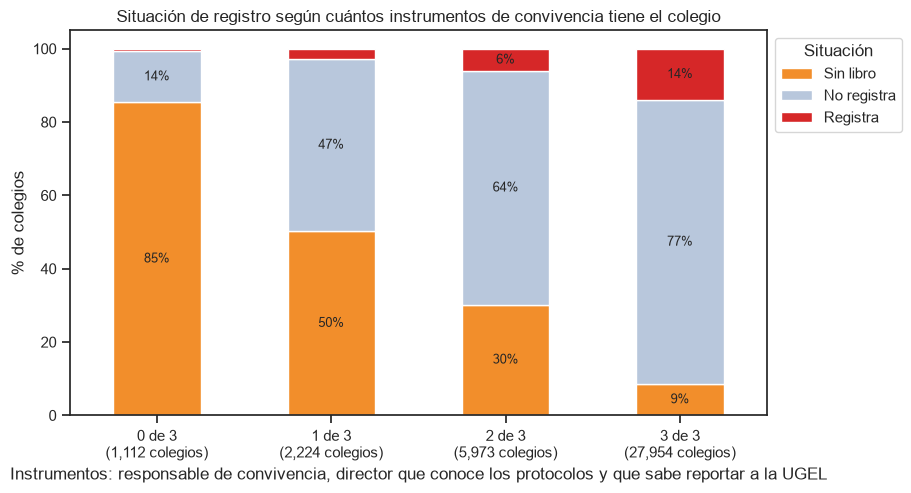

In [19]:
pct_indice = pct_por_situacion("indice_convivencia")
n_indice = colegios_eda["indice_convivencia"].value_counts()
pct_indice.index = [f"{i} de 3\n({n_indice[i]:,} colegios)" for i in pct_indice.index]

ax = pct_indice.plot(kind="bar", stacked=True, rot=0, figsize=(9, 5),
                     color=[colores_situacion[s] for s in orden_situacion])
for barras in ax.containers:
    ax.bar_label(barras, labels=[f"{v:.0f}%" if v >= 3 else "" for v in barras.datavalues],
                 label_type="center", fontsize=9)
ax.set(title="Situación de registro según cuántos instrumentos de convivencia tiene el colegio",
       xlabel="Instrumentos: responsable de convivencia, director que conoce los protocolos y que sabe reportar a la UGEL",
       ylabel="% de colegios")
ax.legend(title="Situación", bbox_to_anchor=(1, 1))
plt.savefig(SALIDAS / "fig_situacion_instrumentos.png", dpi=200, bbox_inches="tight")
plt.show()

*   **Cuantos menos instrumentos tiene el colegio, más probable es que tampoco tenga libro:** entre los que no tienen
    ninguno, el 85 % no tiene libro; entre los que tienen los tres, el 9 %.
*   **También cambia el porcentaje que registra:** de menos del 1 % (ninguno) a 14 % (los tres).
*   Los colegios sin ningún instrumento son pocos (1,112), pero son justamente los que casi no aparecen en el registro.

### <font color=skyblue> 6.2 Gráfico 2 — Repetición según la situación de registro </font>

Se mira si el colegio tiene **repetición alta** (repite el 5 % o más de sus estudiantes). Se separa por área porque los
colegios rurales repiten más y registran menos. Solo entran colegios con 20 o más estudiantes (`MIN_EVALUADOS`).

colegios        pct_repeticion_alta       
DAREACENSO            Rural Urbana               Rural Urbana
situacion_registro                                           
Sin libro              1952   1081                24.3    4.3
No registra            8675   7719                17.4    6.5
Registra               1237   2612                17.3    8.0

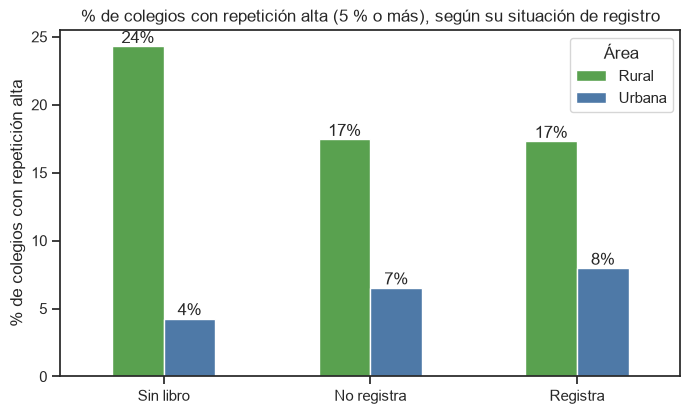

In [20]:
tray = colegios_eda[colegios_eda["res_evaluados"] >= MIN_EVALUADOS].copy()
tray["repeticion_alta"] = tray["tasa_repeticion"] >= 0.05

pct_rep = (tray.groupby(["situacion_registro", "DAREACENSO"])["repeticion_alta"]
           .agg(colegios="size", pct_repeticion_alta=lambda s: s.mean() * 100).unstack().loc[orden_situacion])
display(pct_rep.round(1))

ax = pct_rep["pct_repeticion_alta"].plot(kind="bar", rot=0, figsize=(8, 4.5), color=["#59a14f", "#4e79a7"])
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.0f%%")
ax.set(title="% de colegios con repetición alta (5 % o más), según su situación de registro",
       xlabel="", ylabel="% de colegios con repetición alta")
ax.legend(title="Área")
plt.savefig(SALIDAS / "fig_repeticion_situacion.png", dpi=200, bbox_inches="tight")
plt.show()

*   **En las zonas rurales, los colegios sin libro tienen más repetición alta:** 24 %, frente a 17 % de los que tienen
    libro, registren o no.
*   **Registrar no va junto con repetir más:** en el campo, los que registran y los que no registran tienen la misma
    repetición alta (17 %); en las ciudades la diferencia es pequeña (8 % frente a 6.5 %).
*   Es una descripción: muestra qué ocurre junto, no qué causa qué. El clustering (sección 8) permite ver juntos el
    tamaño, el contexto y los instrumentos del colegio.

## <font color=yellow> 7. Matriz analítica </font>

Se reúnen en una sola tabla las variables que usa el análisis, ya codificadas. **Cada fila sigue siendo un colegio.**

| Transformación | Variable | Por qué |
|---|---|---|
| Binaria 1/0 (el NaN se conserva) | 7 preguntas SI/NO | La media es directamente el % de colegios que responde SI |
| One-hot | Gestión (3 categorías) | No tiene orden: el *label encoding* inventaría uno |
| Una columna 0/1 | Área → `urbano` | Con dos categorías, una columna basta |
| Logaritmo | Matrícula → `log_mat_total` | La asimetría baja de 3.6 a 0.1 |
| Discretización por regla | Incidencias → `registra_incidencia` (0/1) | El 86 % de los colegios con dato anotó 0: los cuantiles valen 0 y no sirven |

No entran el one-hot del departamento (25 columnas casi vacías; se deja `D_DPTO` como etiqueta) ni el tipo de alumnado
por sexo (99 % mixtos). El escalamiento (z-score) se aplica dentro del clustering, sobre los colegios que usa
(sección 8.2).

In [21]:
# Binarias SI/NO -> 1/0
binarias_matriz = {"P123B": "resp_convivencia", "P125B": "tiene_libro", "P128B": "conoce_protocolos",
                   "P129B": "reporta_ugel", "P124B": "afiliado_siseve", "P116A": "actividad_esi",
                   "P127B": "consulta_rnssc"}
codificadas = pd.DataFrame({nueva: base_final[original].map({"SI": 1, "NO": 0})
                            for original, nueva in binarias_matriz.items()})

# Nominal -> one-hot (nombres cortos)
gestion = base_final["D_GESTION"].map({"Pública de gestión directa": "publica",
                                       "Pública de gestión privada": "publica_convenio",
                                       "Privada": "privada"})
dummies_gestion = pd.get_dummies(gestion, prefix="gestion", dtype=int)

# Registra al menos una incidencia (NaN si no hay dato del libro)
registra_incidencia = (base_final["incidencias_libro"] > 0).astype(float).where(base_final["incidencias_libro"].notna())

# Matriz analítica
matriz = base_final[["COD_MOD", "ANEXO", "D_DPTO"]].copy()
numericas = ["mat_total", "pct_mujeres", "incidencias_libro", "casos_siseve", "tasa_incidencias_100",
             "tasa_casos_siseve_100", "tasa_repeticion", "tasa_retiro", "indice_convivencia"]
matriz[numericas] = base_final[numericas].astype(float)
matriz["log_mat_total"] = np.log(matriz["mat_total"])
matriz["registra_incidencia"] = registra_incidencia
matriz = matriz.join(codificadas)
matriz["urbano"] = (base_final["DAREACENSO"] == "Urbana").astype(int)
matriz = matriz.join(dummies_gestion)
matriz["matricula_imputada"] = (base_final["IMPUTADO"] != "1_INFORMANTE").astype(int)

print("Matriz analítica:", matriz.shape, "| ¿una fila por colegio?", matriz.duplicated(subset=LLAVE).sum() == 0)

Matriz analítica: (37354, 26) | ¿una fila por colegio? True


In [22]:
descripcion = {
    "COD_MOD": ("Identificador", "Código modular (llave)"),
    "ANEXO": ("Identificador", "Anexo (llave)"),
    "D_DPTO": ("Etiqueta", "Departamento, para agrupar resultados"),
    "mat_total": ("Numérica", "Matrícula total de primaria 2025"),
    "pct_mujeres": ("Numérica", "Proporción de mujeres matriculadas"),
    "incidencias_libro": ("Numérica", "Incidencias anotadas en el libro en 2024"),
    "casos_siseve": ("Numérica", "Casos reportados al SíseVe hasta la fecha del Censo 2025"),
    "tasa_incidencias_100": ("Derivada", "Incidencias por cada 100 estudiantes"),
    "tasa_casos_siseve_100": ("Derivada", "Casos SíseVe por cada 100 estudiantes"),
    "tasa_repeticion": ("Derivada", "Repitentes (C101 + C201) / matrícula final"),
    "tasa_retiro": ("Derivada", "Retirados / matrícula final"),
    "indice_convivencia": ("Derivada", "Índice de gestión de la convivencia (0 a 3)"),
    "log_mat_total": ("Transformada", "Logaritmo de la matrícula"),
    "registra_incidencia": ("Discretizada", "1 si registró al menos una incidencia"),
    "resp_convivencia": ("Binaria", "Tiene responsable de convivencia (P123B)"),
    "tiene_libro": ("Binaria", "Tiene libro de registro de incidencias (P125B)"),
    "conoce_protocolos": ("Binaria", "El director conoce los protocolos (P128B)"),
    "reporta_ugel": ("Binaria", "Sabe que debe reportar a la UGEL (P129B)"),
    "afiliado_siseve": ("Binaria", "Afiliado al SíseVe (P124B)"),
    "actividad_esi": ("Binaria", "Actividad de ESI con familias (P116A)"),
    "consulta_rnssc": ("Binaria", "Consulta el registro de sancionados (P127B)"),
    "urbano": ("Binaria", "1 si el área es urbana"),
    "gestion_privada": ("One-hot", "Gestión privada"),
    "gestion_publica": ("One-hot", "Pública de gestión directa"),
    "gestion_publica_convenio": ("One-hot", "Pública de gestión privada (convenio)"),
    "matricula_imputada": ("Control", "1 si el MINEDU imputó la matrícula"),
}
diccionario = pd.DataFrame({
    "tipo": [descripcion[c][0] for c in matriz.columns],
    "descripción": [descripcion[c][1] for c in matriz.columns],
    "% faltantes": (matriz.isna().mean() * 100).round(1).values,
}, index=matriz.columns).rename_axis("variable")
display(diccionario)

matriz.to_csv(SALIDAS / "matriz_analitica.csv", index=False)
diccionario.to_csv(SALIDAS / "diccionario_matriz.csv")
print("Guardados:", SALIDAS / "matriz_analitica.csv", "y", SALIDAS / "diccionario_matriz.csv")

,tipo,descripción,% faltantes
variable,,,
COD_MOD,Identificador,Código modular (llave),0.0
ANEXO,Identificador,Anexo (llave),0.0
D_DPTO,Etiqueta,"Departamento, para agrupar resultados",0.0
mat_total,Numérica,Matrícula total de primaria 2025,0.0
pct_mujeres,Numérica,Proporción de mujeres matriculadas,0.0
incidencias_libro,Numérica,Incidencias anotadas en el libro en 2024,15.8
casos_siseve,Numérica,Casos reportados al SíseVe hasta la fecha del ...,0.1
tasa_incidencias_100,Derivada,Incidencias por cada 100 estudiantes,31.5
tasa_casos_siseve_100,Derivada,Casos SíseVe por cada 100 estudiantes,20.5


Guardados: salidas\matriz_analitica.csv y salidas\diccionario_matriz.csv


## <font color=yellow> 8. Método: perfiles de colegios con K-means </font>

Se buscan **perfiles de colegios según su contexto y su capacidad institucional para gestionar la convivencia**.

**¿Por qué K-means?**

*   **Responde al objetivo.** La UGEL necesita saber qué tipos de colegio existen para priorizar. No hay una etiqueta de
    "colegio con baja capacidad" con la que entrenar un modelo: es un problema de agrupamiento (no supervisado).
*   **Se explica fácil.** Cada grupo se describe con el promedio de cada atributo.
*   **Funciona con todos los colegios** (37 mil); el jerárquico solo cabe en memoria con una muestra.
*   **Limitación.** Busca grupos compactos con distancia euclidiana y 8 de los 9 atributos son sí/no. Por eso los grupos
    se comparan con otros métodos (8.5).

**Qué no resuelve.** No separa un colegio sin violencia de uno sin registro, porque los datos no miden la violencia
ocurrida: sirve para priorizar dónde un cero es menos confiable.

### <font color=skyblue> 8.1 Variables que entran a la distancia </font>

| Bloque | Atributo | Origen |
|---|---|---|
| Contexto | `log_mat_total` | Matrícula 2025 (logaritmo) |
| Contexto | `urbano` | Padrón: área censal |
| Contexto | `gestion_privada` | Padrón: tipo de gestión |
| Convivencia | `resp_convivencia` | P123B: ¿cuenta con responsable de convivencia escolar? |
| Convivencia | `afiliado_siseve` | P124B: ¿está afiliado al SíseVe? |
| Convivencia | `conoce_protocolos` | P128B: ¿el director conoce los protocolos de atención de violencia? |
| Convivencia | `reporta_ugel` | P129B: ¿sabe que los hechos deben reportarse también a la UGEL? |
| Convivencia | `consulta_rnssc` | P127B: ¿consulta el Registro Nacional de Sanciones (RNSSC)? |
| Convivencia | `actividad_esi` | P116A: ¿alguna actividad con familias tiene como eje la ESI? |

**No entran a la distancia** (solo se usan para interpretar los grupos):

| Variable(s) | Motivo |
|---|---|
| `registra_incidencia` y tasas de incidencias | Son el **resultado** que se quiere explicar |
| `tiene_libro` | Es el instrumento con el que se registra: incluirlo haría circular el análisis |
| `tasa_repeticion`, `tasa_retiro` | Trayectoria escolar: se comparan después entre grupos |
| `mat_total`, `indice_convivencia` | Repiten `log_mat_total` y tres de los instrumentos |
| `pct_mujeres` | Describe al alumnado, no la capacidad ni el contexto del colegio |
| `gestion_publica`, `gestion_publica_convenio` | Redundante con `gestion_privada` / solo el 1.2 % de los colegios |

In [23]:
atributos_km = ["log_mat_total", "urbano", "gestion_privada",          # contexto
                "resp_convivencia", "afiliado_siseve", "conoce_protocolos",
                "reporta_ugel", "consulta_rnssc", "actividad_esi"]       # instrumentos de convivencia

# Nombres cortos para que las tablas y gráficos se lean fácil
nombres_cortos = {"log_mat_total": "Matrícula (log)", "urbano": "Urbano", "gestion_privada": "Privado",
                  "resp_convivencia": "Responsable de convivencia", "afiliado_siseve": "Afiliado al SíseVe",
                  "conoce_protocolos": "Conoce protocolos", "reporta_ugel": "Sabe reportar a la UGEL",
                  "consulta_rnssc": "Consulta RNSSC", "actividad_esi": "ESI con familias"}

# K-means no admite faltantes: se usan los colegios con los 9 atributos completos
datos_km = matriz.dropna(subset=atributos_km).copy()
X_km = datos_km[atributos_km].astype(float)     # unidades originales -> para perfilar
print(f"Colegios para clustering: {len(datos_km):,} de {len(matriz):,} ({len(datos_km) / len(matriz):.1%})")
display(X_km.describe().T[["mean", "std", "min", "max"]].round(3))

Colegios para clustering: 37,260 de 37,354 (99.7%)


,mean,std,min,max
log_mat_total,3.533,1.477,0.0,7.712
urbano,0.330,0.470,0.0,1.000
gestion_privada,0.210,0.407,0.0,1.000
resp_convivencia,0.871,0.335,0.0,1.000
afiliado_siseve,0.823,0.382,0.0,1.000
conoce_protocolos,0.871,0.335,0.0,1.000
reporta_ugel,0.888,0.315,0.0,1.000
consulta_rnssc,0.442,0.497,0.0,1.000
actividad_esi,0.441,0.497,0.0,1.000


### <font color=skyblue> 8.2 Escalamiento </font>

`log_mat_total` va de 0 a 7.7 y las otras 8 variables de 0 a 1: sin escalar, la matrícula dominaría la distancia. Se usa
**`StandardScaler`** (z-score). Min-max no sirve aquí: un solo colegio muy grande comprimiría al resto.

> **Efecto a tener en cuenta:** en una binaria poco frecuente, el z-score amplifica la categoría rara (el 13 % sin
> responsable de convivencia queda en z ≈ −2.6). Por eso *no tener* un instrumento pesa más en la distancia que tenerlo,
> que es justamente lo que interesa al problema.

In [24]:
X_std_km = StandardScaler().fit_transform(X_km)
display(pd.DataFrame(X_std_km, columns=atributos_km).describe().T[["mean", "std", "min", "max"]].round(2))

,mean,std,min,max
log_mat_total,0.0,1.0,-2.39,2.83
urbano,-0.0,1.0,-0.70,1.42
gestion_privada,-0.0,1.0,-0.52,1.94
resp_convivencia,-0.0,1.0,-2.60,0.38
afiliado_siseve,-0.0,1.0,-2.16,0.46
conoce_protocolos,-0.0,1.0,-2.60,0.38
reporta_ugel,-0.0,1.0,-2.82,0.35
consulta_rnssc,0.0,1.0,-0.89,1.12
actividad_esi,-0.0,1.0,-0.89,1.13


### <font color=skyblue> 8.3 Elección de K </font>

| Métrica | Qué mide | Mejor |
|---|---|---|
| **Inercia** (codo) | Qué tan cerca está cada colegio del centro de su grupo | Donde deja de bajar mucho |
| **Silueta** (−1 a 1) | Si cada colegio está más cerca de su grupo que del grupo vecino | Más alta |
| **Davies-Bouldin** | Si los grupos son compactos y están lejos unos de otros | Más bajo |

La silueta compara cada colegio con todos los demás; con 37 mil colegios se calcula sobre una **muestra de 10,000**.

,k,inercia,silueta,davies_bouldin
0,2,261769.727,0.263,1.658
1,3,211762.153,0.290,1.451
2,4,189733.913,0.239,1.480
3,5,171916.559,0.255,1.473
4,6,153071.359,0.285,1.459


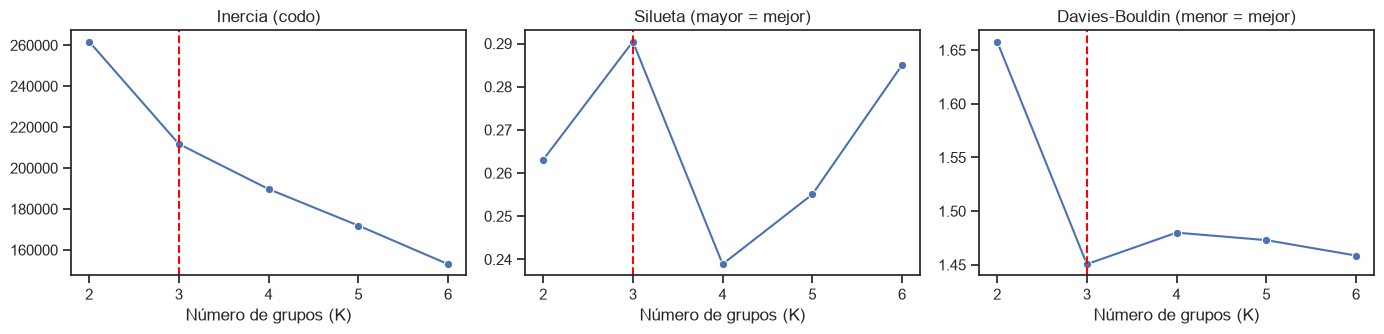

In [25]:
validacion = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42).fit(X_std_km)
    validacion.append({
        "k": k,
        "inercia": km.inertia_,
        "silueta": silhouette_score(X_std_km, km.labels_, sample_size=10_000, random_state=42),
        "davies_bouldin": davies_bouldin_score(X_std_km, km.labels_),
    })
validacion = pd.DataFrame(validacion)
display(validacion.round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
titulos = ["Inercia (codo)", "Silueta (mayor = mejor)", "Davies-Bouldin (menor = mejor)"]
for ax, columna, titulo in zip(axes, ["inercia", "silueta", "davies_bouldin"], titulos):
    sns.lineplot(data=validacion, x="k", y=columna, marker="o", ax=ax)
    ax.axvline(3, color="red", ls="--")
    ax.set(title=titulo, xlabel="Número de grupos (K)", ylabel="")
plt.tight_layout()
plt.savefig(SALIDAS / "fig_validacion_k.png", dpi=200, bbox_inches="tight")
plt.show()

K = 3 tiene la silueta más alta (0.290) y el Davies-Bouldin más bajo (1.451), y coincide con el codo. K = 6 se acerca
mucho (0.285 y 1.459). Una silueta cercana a 0.3 indica una estructura débil: hay colegios intermedios entre grupos.

**¿Es estable?** Se repite la silueta con otras 5 muestras y K-means con otros 4 puntos de partida. El **ARI** compara
dos agrupaciones: 1 = los mismos grupos; 0 = coinciden como por azar.

In [26]:
estabilidad = []
for k in range(2, 7):
    etiquetas_k = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42).fit_predict(X_std_km)
    siluetas = [silhouette_score(X_std_km, etiquetas_k, sample_size=10_000, random_state=r) for r in range(5)]
    parecidos = [adjusted_rand_score(etiquetas_k, KMeans(n_clusters=k, init="k-means++", n_init=10,
                                                         random_state=r).fit_predict(X_std_km))
                 for r in [1, 7, 21, 99]]
    estabilidad.append({"k": k, "silueta_min": min(siluetas), "silueta_max": max(siluetas),
                        "ARI_min": min(parecidos), "ARI_max": max(parecidos)})
pd.DataFrame(estabilidad).round(3)

,k,silueta_min,silueta_max,ARI_min,ARI_max
0,2,0.261,0.267,1.000,1.000
1,3,0.288,0.295,1.000,1.000
2,4,0.238,0.245,0.946,1.000
3,5,0.254,0.262,0.401,0.779
4,6,0.283,0.292,0.447,0.982


Por silueta, K = 3 y K = 6 **no se pueden separar** (sus rangos se traslapan). Lo que sí los separa es la estabilidad:
con K = 3 los grupos son idénticos en todas las corridas (ARI = 1.0), mientras que con K = 5 y K = 6 cambian bastante.
K = 2 es estable, pero con peores métricas. **Se elige K = 3**: la configuración más estable entre las de mejor métrica y
la más simple de explicar a la UGEL.

### <font color=skyblue> 8.4 K-means con K = 3 y perfil de los grupos </font>

Colegios por grupo:


grupo
Urbano grande             11460
Rural con instrumentos    20725
Pocos instrumentos         5075
Name: count, dtype: int64

grupo,Urbano grande,Rural con instrumentos,Pocos instrumentos
Matrícula (log),4.90,2.94,2.87
Urbano,1.00,0.00,0.16
Privado,0.61,0.00,0.15
Responsable de convivencia,0.95,0.95,0.37
Afiliado al SíseVe,0.93,0.90,0.25
Conoce protocolos,0.97,0.95,0.32
Sabe reportar a la UGEL,0.95,0.96,0.45
Consulta RNSSC,0.64,0.41,0.11
ESI con familias,0.48,0.48,0.20


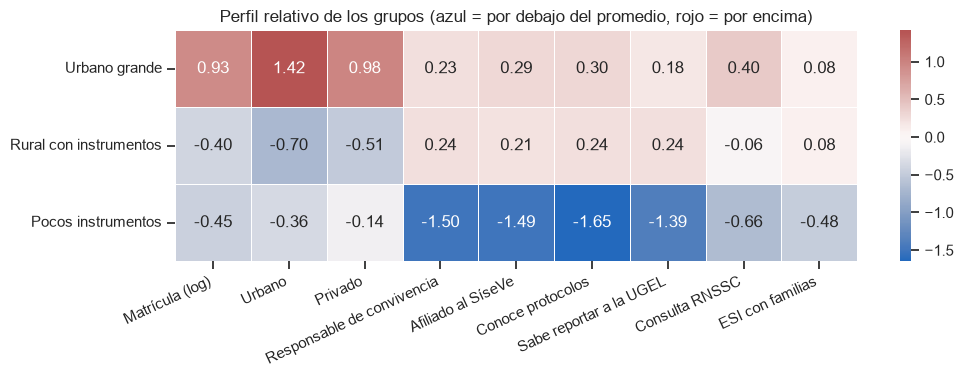

In [27]:
kmeans = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=42)
datos_km["cluster_kmeans"] = kmeans.fit_predict(X_std_km)
matriz["cluster_kmeans"] = datos_km["cluster_kmeans"]

# Nombre de cada grupo según su perfil, no según el número que asigna K-means
perfil_clusters = datos_km.groupby("cluster_kmeans")[["resp_convivencia", "mat_total"]].mean()
c_pocos = perfil_clusters["resp_convivencia"].idxmin()             # menos responsables de convivencia
c_urbano = perfil_clusters.drop(c_pocos)["mat_total"].idxmax()     # de los otros dos, el más grande
nombres_cluster = {c: "Rural con instrumentos" for c in perfil_clusters.index}
nombres_cluster.update({c_pocos: "Pocos instrumentos", c_urbano: "Urbano grande"})
orden_grupos = ["Urbano grande", "Rural con instrumentos", "Pocos instrumentos"]

grupos = datos_km["cluster_kmeans"].map(nombres_cluster).rename("grupo")
print("Colegios por grupo:")
display(grupos.value_counts()[orden_grupos])

# Perfil en unidades originales (proporción de colegios con cada atributo)
perfil = datos_km.groupby(grupos)[atributos_km].mean().loc[orden_grupos]
display(perfil.rename(columns=nombres_cortos).T.round(2))

# Perfil relativo (z-score del promedio de cada grupo)
perfil_z = (perfil - X_km.mean()) / X_km.std(ddof=0)
plt.figure(figsize=(11, 3))
sns.heatmap(perfil_z.rename(columns=nombres_cortos), annot=True, fmt=".2f", center=0, cmap="vlag", linewidths=0.5)
plt.title("Perfil relativo de los grupos (azul = por debajo del promedio, rojo = por encima)")
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=25, ha="right")
plt.savefig(SALIDAS / "fig_perfil_kmeans.png", dpi=200, bbox_inches="tight")
plt.show()

**Interpretación de los grupos con variables que no entraron al modelo.** `registra_incidencia` solo existe para los
colegios con dato del libro (casi todos los sin libro quedan fuera), así que se muestra la base de cada porcentaje.

In [28]:
por_grupo = datos_km.groupby(grupos)
interpretacion = pd.DataFrame({
    "colegios": grupos.value_counts(),
    "matrícula media": por_grupo["mat_total"].mean().round(0),
    "% sin libro": (1 - por_grupo["tiene_libro"].mean()) * 100,
    "con dato de registro": por_grupo["registra_incidencia"].count(),
    "registran": por_grupo["registra_incidencia"].sum().astype(int),
    "% que registra": por_grupo["registra_incidencia"].mean() * 100,
    "repetición media (%)": por_grupo["tasa_repeticion"].mean() * 100,
    "retiro medio (%)": por_grupo["tasa_retiro"].mean() * 100,
}).loc[orden_grupos]
display(interpretacion.round(1))

# Los colegios grandes registran más: % que registra a igual tamaño (y colegios con dato en cada celda)
tamano = pd.cut(datos_km["mat_total"], [0, 20, 50, 100, np.inf], include_lowest=True,
                labels=["Hasta 20", "21 a 50", "51 a 100", "Más de 100"])
print("% que registra, por tamaño del colegio:")
display((datos_km.pivot_table(index=grupos, columns=tamano, values="registra_incidencia",
                              aggfunc="mean", observed=True) * 100).loc[orden_grupos].round(1))
print("Colegios con dato en cada celda:")
display(datos_km.pivot_table(index=grupos, columns=tamano, values="registra_incidencia",
                             aggfunc="count", observed=True).loc[orden_grupos])

,colegios,matrícula media,% sin libro,con dato de registro,registran,% que registra,repetición media (%),retiro medio (%)
grupo,,,,,,,,
Urbano grande,11460,237.0,7.3,10656,2614,24.5,1.2,0.5
Rural con instrumentos,20725,35.0,11.7,18457,1615,8.8,2.1,0.3
Pocos instrumentos,5075,36.0,58.9,2265,125,5.5,2.4,0.5


% que registra, por tamaño del colegio:


mat_total,Hasta 20,21 a 50,51 a 100,Más de 100
grupo,,,,
Urbano grande,3.4,7.1,11.4,33.3
Rural con instrumentos,4.9,9.0,15.0,22.8
Pocos instrumentos,3.1,7.9,7.0,13.0


Colegios con dato en cada celda:


mat_total,Hasta 20,21 a 50,51 a 100,Más de 100
grupo,,,,
Urbano grande,586,1193,2045,6832
Rural con instrumentos,9343,5321,2434,1359
Pocos instrumentos,1239,559,313,154


*   **Urbano grande** (11,460): urbanos, más grandes, 61 % privados y con los instrumentos. Registra el 24.5 %, pero en
    buena parte por su tamaño: solo supera al grupo rural en los colegios de más de 100 estudiantes.
*   **Rural con instrumentos** (20,725): públicos, rurales y pequeños, con casi todos los instrumentos. Registra el 8.8 %.
*   **Pocos instrumentos** (5,075): pequeños, sobre todo rurales; solo el 37 % tiene responsable de convivencia y el
    **59 % no tiene libro** (dato que no entró al modelo). Registra el 5.5 % (125 de 2,265 con dato), **menos que el grupo
    rural en los cuatro tamaños** (de 3.1 % frente a 4.9 % hasta 13.0 % frente a 22.8 %).
*   La repetición media es mayor en *Pocos instrumentos* (2.4 %) y en el grupo rural (2.1 %) que en el urbano (1.2 %);
    el retiro es bajo y parecido en los tres (0.3 % a 0.5 %).

### <font color=skyblue> 8.5 ¿Los grupos dependen del método? </font>

Se comparan los grupos de K-means con tres alternativas sobre los mismos colegios:

*   **Jerárquico Ward:** otro algoritmo. Compara todos los colegios contra todos, así que se construye con una muestra
    de 10,000 y se corta en 3 grupos.
*   **K-means sobre las componentes del PCA** que conservan el 80 % de la varianza: ¿hace falta reducir la dimensión?
*   **K-means sin escalar:** ¿importa el z-score?

In [29]:
def coincidencia(etiquetas_a, etiquetas_b):
    # % de colegios que caen en el grupo equivalente (el de mayor coincidencia)
    return pd.crosstab(etiquetas_a, etiquetas_b).max(axis=1).sum() / len(etiquetas_a) * 100

etiquetas_km = datos_km["cluster_kmeans"].to_numpy()

# 1) Jerárquico Ward sobre una muestra de 10,000 colegios
muestra = np.random.default_rng(42).choice(len(X_std_km), size=10_000, replace=False)
etiquetas_ward = fcluster(linkage(X_std_km[muestra], method="ward"), t=3, criterion="maxclust")

# 2) K-means sobre las componentes del PCA que conservan el 80 % de la varianza
Z_pca = PCA(n_components=0.80).fit_transform(X_std_km)
etiquetas_pca = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(Z_pca)

# 3) K-means sin escalar
etiquetas_sin_escalar = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X_km)

robustez = pd.DataFrame([
    ["Jerárquico Ward (muestra de 10,000)", adjusted_rand_score(etiquetas_km[muestra], etiquetas_ward),
     coincidencia(etiquetas_ward, etiquetas_km[muestra])],
    [f"K-means sobre {Z_pca.shape[1]} componentes PCA", adjusted_rand_score(etiquetas_km, etiquetas_pca),
     coincidencia(etiquetas_pca, etiquetas_km)],
    ["K-means sin escalar", adjusted_rand_score(etiquetas_km, etiquetas_sin_escalar),
     coincidencia(etiquetas_sin_escalar, etiquetas_km)],
], columns=["alternativa", "ARI con K-means", "% en el grupo equivalente"])
display(robustez.round(3))

print("Sin escalar, ¿qué separa a los grupos?")
display(X_km.groupby(etiquetas_sin_escalar)[["log_mat_total", "urbano", "resp_convivencia", "conoce_protocolos"]].mean().round(2))

,alternativa,ARI con K-means,% en el grupo equivalente
0,"Jerárquico Ward (muestra de 10,000)",0.759,90.020
1,K-means sobre 6 componentes PCA,0.995,99.842
2,K-means sin escalar,0.263,75.926


Sin escalar, ¿qué separa a los grupos?


,log_mat_total,urbano,resp_convivencia,conoce_protocolos
0,1.83,0.05,0.81,0.80
1,5.33,0.87,0.94,0.95
2,3.53,0.16,0.87,0.87


*   **El jerárquico llega a grupos parecidos por un camino distinto:** el 90 % de los colegios de la muestra cae en el
    grupo equivalente (ARI 0.76). Su principal diferencia es que pasa parte del grupo rural a *Pocos instrumentos*.
*   **Reducir la dimensión no hace falta:** con las 6 componentes del PCA los grupos son casi idénticos (ARI 0.995), así
    que se usan los 9 atributos, que se leen directo.
*   **El escalamiento sí importa:** sin z-score los grupos cambian por completo (ARI 0.26) y se separan sobre todo por
    tamaño, con poca diferencia en los instrumentos.

**Resultado del método.** K = 3 es estable y los perfiles no dependen del algoritmo, aunque la separación entre grupos
es débil (silueta 0.29): los grupos sirven para **priorizar**, no para clasificar de forma definitiva.

### <font color=skyblue> 8.6 Complemento: ¿qué faltas van juntas? (reglas de asociación) </font>

K-means describe tipos de colegio; Apriori responde otra pregunta: **si a un colegio le falta un instrumento, ¿qué más
le falta?** Cada colegio es una "canasta" con los instrumentos que **no** tiene, más si es rural. Se piden reglas de hasta 3
ítems con:

*   **Confianza ≥ 0.7**, dentro del rango recomendado en clase (70 – 90 %): de cada 10 colegios con el antecedente, al
    menos 7 tienen también el consecuente.
*   **Lift ≥ 2**: la falta debe ser al menos el doble de probable que en un colegio cualquiera.
*   **Soporte ≥ 1 %** (≥ 374 colegios). Queda por debajo del rango orientativo de clase (2 – 10 %) a propósito: 374
    colegios ya justifican un programa de la UGEL, y algunas faltas son poco comunes (solo el 5.8 % no tiene normas).

In [30]:
# Cada colegio es una transacción: los instrumentos que le faltan y si es rural
faltas = pd.DataFrame({
    "sin responsable":       base_final["P123B"].eq("NO"),
    "sin protocolos":        base_final["P128B"].eq("NO"),
    "no reporta a la UGEL":  base_final["P129B"].eq("NO"),
    "no afiliado al SíseVe": base_final["P124B"].eq("NO"),
    "sin plan TOECE":        base_final["P103B"].eq("NO"),
    "sin normas":            base_final["P121B"].eq("NO"),
    "sin libro":             base_final["P125B"].eq("NO"),
    "rural":                 base_final["DAREACENSO"].eq("Rural"),
})
records = [list(faltas.columns[fila]) for fila in faltas.to_numpy()]

resultados = list(apriori(records, min_support=0.01, min_confidence=0.7, min_lift=2, max_length=3))

# Tabla de reglas (como en el laboratorio): antecedente -> consecuente
filas = []
for r in resultados:
    for o in r.ordered_statistics:
        if o.items_base:  # se omiten las reglas sin antecedente
            filas.append([", ".join(sorted(o.items_base)), ", ".join(sorted(o.items_add)),
                          round(r.support * len(records)), o.confidence, o.lift])
reglas = pd.DataFrame(filas, columns=["si", "entonces", "colegios (si y entonces)", "confianza", "lift"])

print("Colegios:", len(records), "| reglas encontradas:", len(reglas),
      f"| 'sin libro' en todos los colegios: {faltas['sin libro'].mean():.1%}")
print("Reglas que terminan en 'sin libro' (las 10 de mayor lift):")
display(reglas[reglas["entonces"] == "sin libro"].sort_values("lift", ascending=False).head(10).round(2))

Colegios: 37354 | reglas encontradas: 29 | 'sin libro' en todos los colegios: 16.8%
Reglas que terminan en 'sin libro' (las 10 de mayor lift):


,si,entonces,colegios (si y entonces),confianza,lift
10,"no reporta a la UGEL, sin normas",sin libro,778,0.82,4.87
21,"sin normas, sin protocolos",sin libro,941,0.80,4.77
4,"no afiliado al SíseVe, sin normas",sin libro,927,0.79,4.69
23,"sin normas, sin responsable",sin libro,1002,0.77,4.60
12,"no reporta a la UGEL, sin responsable",sin libro,1112,0.77,4.59
20,"sin normas, sin plan TOECE",sin libro,1140,0.74,4.43
25,"sin protocolos, sin responsable",sin libro,1415,0.73,4.36
5,"no afiliado al SíseVe, sin plan TOECE",sin libro,1810,0.71,4.23
24,"sin plan TOECE, sin protocolos",sin libro,1528,0.70,4.20
1,"no afiliado al SíseVe, no reporta a la UGEL",sin libro,1336,0.70,4.18


**Verificamos con las fórmulas de clase.** Se recalcula a mano la regla más fuerte, contando colegios:

*   soporte = σ(A ∪ B) / N
*   confianza = σ(A ∪ B) / σ(A)
*   lift = confianza / soporte(B)

Con la misma fórmula se mira qué pasa con **una sola falta** o **solo por ser rural**: esas reglas no pasan el filtro
de confianza, así que no aparecen en la tabla.

In [31]:
B = faltas["sin libro"]                                        # consecuente
A = faltas["no reporta a la UGEL"] & faltas["sin normas"]      # antecedente de la regla más fuerte
N = len(faltas)
n_A, n_AB = A.sum(), (A & B).sum()
print("no reporta a la UGEL, sin normas → sin libro")
print(f"  soporte   = {n_AB} / {N} = {n_AB / N:.4f}")
print(f"  confianza = {n_AB} / {n_A} = {n_AB / n_A:.2f}")
print(f"  lift      = {n_AB / n_A:.2f} / {B.mean():.3f} = {n_AB / n_A / B.mean():.2f}")

# Una sola falta, o solo ser rural
print()
for x in ["sin responsable", "sin normas", "rural"]:
    confianza = (faltas[x] & B).sum() / faltas[x].sum()
    print(f"{x} → sin libro: confianza {confianza:.2f}, lift {confianza / B.mean():.2f}")

no reporta a la UGEL, sin normas → sin libro
  soporte   = 778 / 37354 = 0.0208
  confianza = 778 / 951 = 0.82
  lift      = 0.82 / 0.168 = 4.87

sin responsable → sin libro: confianza 0.52, lift 3.12
sin normas → sin libro: confianza 0.65, lift 3.90
rural → sin libro: confianza 0.20, lift 1.18


*   **Las faltas vienen juntas.** Al colegio que le faltan dos instrumentos, entre el 70 % y el 82 % tampoco tiene libro,
    frente al 16.8 % del total (lift de 4.2 a 4.9). Con una sola falta la confianza baja y no pasa el filtro (sin
    responsable → sin libro: 52 %; la más alta, sin normas → sin libro: 65 %).
*   Ejemplo: 1,112 colegios no tienen responsable, no reportan a la UGEL y no tienen libro; es el 77 % de los que no
    tienen responsable ni reportan.
*   **Ser rural, por sí solo, casi no anticipa la falta de libro:** el 20 % de los colegios rurales no tiene libro,
    frente al 16.8 % del total (lift 1.2). Lo que anticipa la falta del libro son las otras faltas, no el área.
*   Para la UGEL: dar solo el libro no basta. Donde falta uno, suelen faltar varios, así que conviene **intervenir con el
    paquete completo** (libro, responsable y protocolos). Son asociaciones, no causas.

## <font color=yellow> 9. ¿Dónde están los colegios con menos capacidad de registro? </font>

| Paso | Pregunta | Qué entra al modelo |
|---|---|---|
| 9.1 Grupos de K-means en el mapa | ¿Los perfiles forman regiones? | Nada nuevo: los grupos de la sección 8 (sin la ubicación) |
| 9.2 DBSCAN espacial | ¿Dónde se juntan muchos colegios sin libro? | **Solo** la ubicación de los colegios sin libro, en metros |
| 9.3 Mapa interactivo | ¿A qué colegios ir primero? | Lo anterior, en un mapa para la UGEL |

Se usan los límites de departamentos del IGN (2020). El código busca la carpeta `peru_shapes/` junto al notebook; si no
existe pero está `peru_shapes.zip`, la descomprime.

In [32]:
import zipfile

import geopandas as gpd

CARPETA_SHAPES = Path("peru_shapes")
if not CARPETA_SHAPES.exists() and Path("peru_shapes.zip").exists():
    with zipfile.ZipFile("peru_shapes.zip") as archivo_zip:
        archivo_zip.extractall(CARPETA_SHAPES)
if not (CARPETA_SHAPES / "per_admbnda_adm1_ign_20200714.shp").exists():
    raise FileNotFoundError("Falta la carpeta peru_shapes/ con los shapefiles del IGN. "
                            "Súbanla junto al notebook (en Colab: panel Archivos) o coloquen peru_shapes.zip.")

regiones = gpd.read_file(CARPETA_SHAPES / "per_admbnda_adm1_ign_20200714.shp")   # 25 departamentos

# Una fila por colegio. Los dos primeros dígitos del ubigeo con el prefijo "PE" son el código del shapefile
geo = base_final[LLAVE + ["CODGEO_padron", "D_DPTO", "D_PROV", "NLAT_IE", "NLONG_IE"]].copy()
geo["ADM1_PCODE"] = "PE" + geo["CODGEO_padron"].str[:2]
geo["registra"] = matriz["registra_incidencia"] == 1
geo["sin_libro"] = base_final["P125B"] == "NO"
geo["grupo_kmeans"] = grupos

colegios_gdf = gpd.GeoDataFrame(geo, geometry=gpd.points_from_xy(geo["NLONG_IE"], geo["NLAT_IE"]), crs="EPSG:4326")
print("Colegios en el mapa:", len(colegios_gdf),
      "| sin departamento en el shapefile:", (~colegios_gdf["ADM1_PCODE"].isin(regiones["ADM1_PCODE"])).sum())

Colegios en el mapa: 37354 | sin departamento en el shapefile: 0


### <font color=skyblue> 9.1 Los grupos de K-means en el mapa </font>

K-means no usó la ubicación. Si los grupos forman regiones, el patrón geográfico **sale de las características del
colegio**.

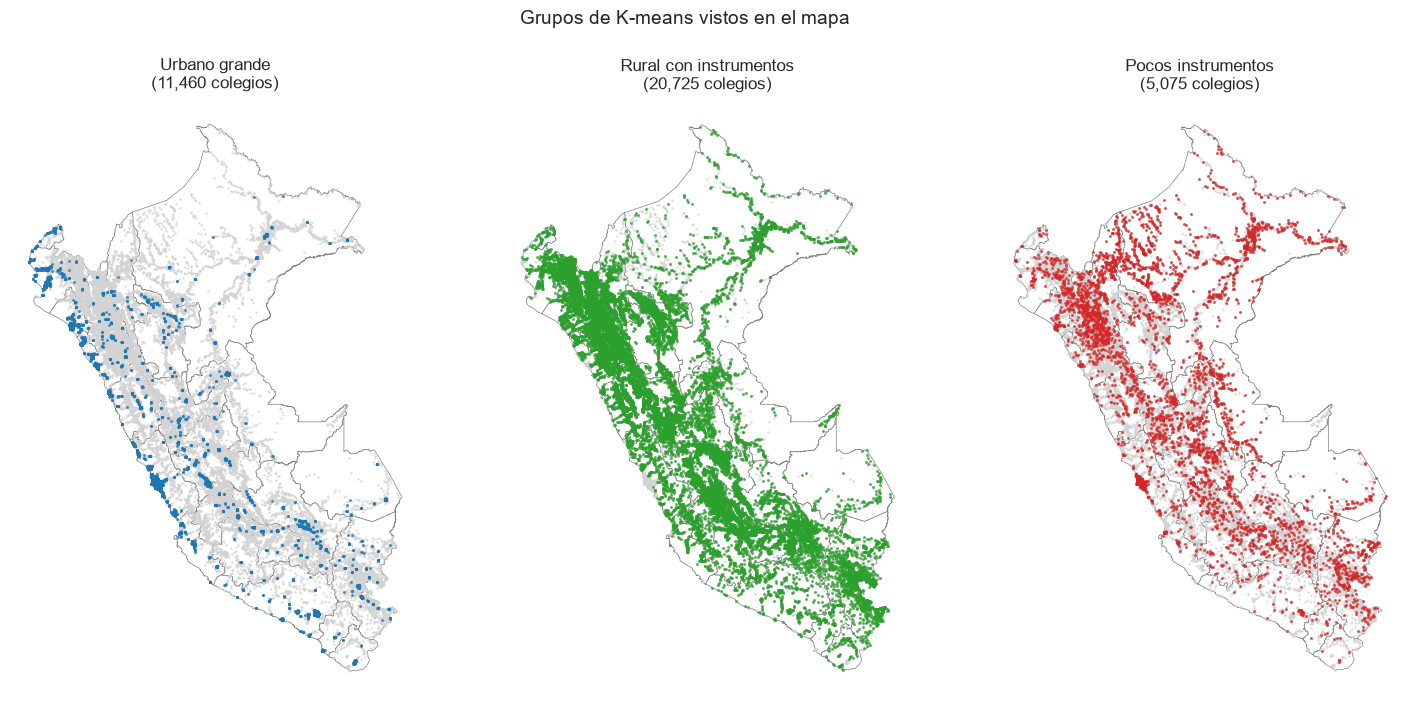

Departamentos con más y con menos colegios del grupo Pocos instrumentos:


,colegios,% Pocos instrumentos,% sin libro,% que registra
ADM1_ES,,,,
Loreto,2376,43.3,50.9,7.1
Ucayali,842,32.4,37.5,8.4
Madre de Dios,218,28.9,25.7,11.9
Pasco,707,24.8,15.4,9.5
Amazonas,1294,23.9,22.7,12.0
Puno,1937,18.2,20.4,6.0
Arequipa,1311,5.1,8.7,17.5
Tumbes,179,5.0,8.9,22.3
Tacna,239,3.8,2.5,22.2


In [33]:
colores_grupo = {"Urbano grande": "tab:blue", "Rural con instrumentos": "tab:green", "Pocos instrumentos": "tab:red"}
fig, axes = plt.subplots(1, 3, figsize=(18, 8))
for ax, (grupo, color) in zip(axes, colores_grupo.items()):
    regiones.plot(ax=ax, facecolor="white", edgecolor="gray", linewidth=0.5)
    colegios_gdf.plot(ax=ax, color="lightgray", markersize=0.3)
    capa = colegios_gdf[colegios_gdf["grupo_kmeans"] == grupo]
    capa.plot(ax=ax, color=color, markersize=1.5, alpha=0.6)
    ax.set_title(f"{grupo}\n({len(capa):,} colegios)")
    ax.set_axis_off()
fig.suptitle("Grupos de K-means vistos en el mapa", fontsize=14)
plt.savefig(SALIDAS / "fig_mapa_grupos.png", dpi=200, bbox_inches="tight")
plt.show()

# Por departamento: % de colegios en "Pocos instrumentos", % sin libro y % que registra
por_dpto = colegios_gdf.groupby("ADM1_PCODE").agg(
    colegios=("COD_MOD", "size"),
    pct_pocos=("grupo_kmeans", lambda s: s.eq("Pocos instrumentos").sum() / s.notna().sum() * 100),
    pct_sin_libro=("sin_libro", lambda s: s.mean() * 100),
    pct_registra=("registra", lambda s: s.mean() * 100),
)
mapa_dpto = regiones.merge(por_dpto, on="ADM1_PCODE", how="left")
tabla_dpto = (mapa_dpto.set_index("ADM1_ES")[["colegios", "pct_pocos", "pct_sin_libro", "pct_registra"]]
              .rename(columns={"pct_pocos": "% Pocos instrumentos", "pct_sin_libro": "% sin libro",
                               "pct_registra": "% que registra"})
              .sort_values("% Pocos instrumentos", ascending=False))
print("Departamentos con más y con menos colegios del grupo Pocos instrumentos:")
display(pd.concat([tabla_dpto.head(6), tabla_dpto.tail(3)]).round(1))

*   Los grupos forman regiones: **Urbano grande** está en la costa y en las ciudades; **Rural con instrumentos** cubre
    casi toda la sierra; **Pocos instrumentos** sigue los ríos de la Amazonía y aparece también en Cajamarca y Puno.
*   El 43 % de los colegios de Loreto está en *Pocos instrumentos* (Ucayali 32 %, Madre de Dios 29 %), y son también los
    departamentos con más colegios sin libro (Loreto 51 %, Ucayali 38 %). En Tacna y Tumbes, en cambio, casi todos
    tienen libro y más del 20 % registra.

### <font color=skyblue> 9.2 DBSCAN espacial: ¿dónde se juntan los colegios sin libro? </font>

Ahora se usa **solo la ubicación** de los 6,269 colegios **sin libro**. DBSCAN forma una zona cuando hay al menos
`min_samples` colegios a menos de `eps` de distancia; los colegios aislados quedan como **ruido** (`-1`). Una zona así
sirve para planear: una sola capacitación o visita de la UGEL puede llegar a muchos colegios sin libro a la vez.

`eps` es una distancia, así que las coordenadas se pasan a **metros** con la proyección UTM 18S (EPSG:32718), la del
centro del país. Se fija `min_samples = 30` (interesan zonas con **muchos** colegios sin libro) y se elige `eps`:

In [34]:
sin_libro_m = colegios_gdf[colegios_gdf["sin_libro"]].to_crs("EPSG:32718")
regiones_m = regiones.to_crs("EPSG:32718")
coords_m = np.column_stack([sin_libro_m.geometry.x, sin_libro_m.geometry.y])   # X e Y en metros

MIN_COLEGIOS = 30
distancias, _ = NearestNeighbors(n_neighbors=MIN_COLEGIOS).fit(coords_m).kneighbors(coords_m)
print(f"Distancia al 30.º vecino sin libro: mediana {np.median(distancias[:, -1]) / 1000:.0f} km, "
      f"percentil 90 {np.percentile(distancias[:, -1], 90) / 1000:.0f} km")

filas = []
for eps_km in [10, 20, 30, 40, 50]:
    etiquetas = DBSCAN(eps=eps_km * 1000, min_samples=MIN_COLEGIOS).fit_predict(coords_m)
    tamanos = pd.Series(etiquetas[etiquetas != -1]).value_counts()
    filas.append({"eps (km)": eps_km, "zonas": len(tamanos), "% ruido": round((etiquetas == -1).mean() * 100),
                  "zona más grande (colegios)": tamanos.max()})
display(pd.DataFrame(filas))

Distancia al 30.º vecino sin libro: mediana 30 km, percentil 90 60 km


,eps (km),zonas,% ruido,zona más grande (colegios)
0,10,6,87,594
1,20,22,60,611
2,30,22,34,1689
3,40,15,16,3435
4,50,8,7,5159


Con `eps = 10 km` casi todo es ruido (87 %); con 40 o 50 km aparecen zonas gigantes que unen varios departamentos. Se
usa **`eps = 30 km`** (la mediana de la distancia al 30.º vecino): deja 22 zonas y un tercio de ruido, a una escala
parecida a la de una provincia.

Zonas: 22 | colegios como ruido: 2106 (34%)


,colegios_sin_libro,departamentos,provincia_principal,% sin libro en la provincia
zona,,,,
0,1689,"Cajamarca, Piura",CELENDIN,39.7
4,619,"Lima, Callao",LIMA,12.2
7,244,Loreto,MAYNAS,42.1
2,230,Puno,AZANGARO,23.2
9,205,"Amazonas, Loreto",CONDORCANQUI,60.5
5,173,"Junin, Pasco",SATIPO,21.2
6,161,"Loreto, San Martin",ALTO AMAZONAS,40.9
1,114,"Ucayali, Huanuco",CORONEL PORTILLO,36.9


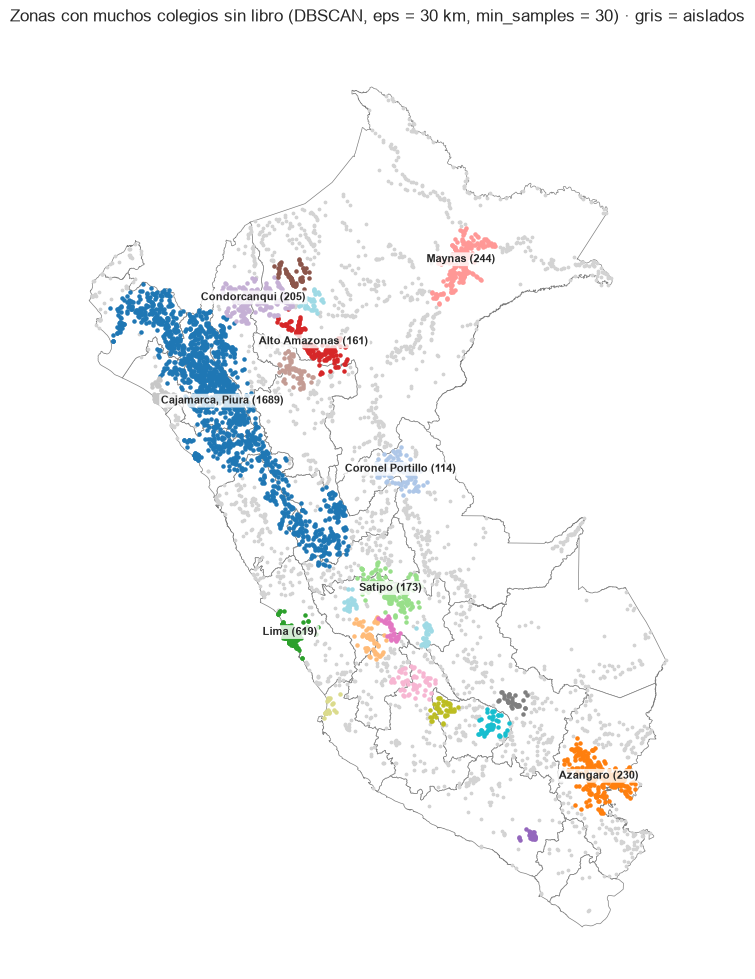

Colegios sin libro aislados (ruido) -> Amazonía: 56% | resto del país: 26%
Provincias con mayor % de colegios sin libro:


D_DPTO    D_PROV           
LORETO    DATEM DEL MARAÑON    85.3
UCAYALI   PURUS                81.6
LORETO    PUTUMAYO             68.6
AMAZONAS  CONDORCANQUI         60.5
LORETO    LORETO               50.0
Name: sin_libro, dtype: float64

In [35]:
sin_libro_m["zona"] = DBSCAN(eps=30_000, min_samples=MIN_COLEGIOS).fit_predict(coords_m)
ruido = sin_libro_m[sin_libro_m["zona"] == -1]
zonas = sin_libro_m[sin_libro_m["zona"] != -1]
print(f"Zonas: {zonas['zona'].nunique()} | colegios como ruido: {len(ruido)} ({len(ruido) / len(sin_libro_m):.0%})")

# Resumen de cada zona: cuántos colegios y dónde está
resumen_zonas = (zonas.groupby("zona")
                 .agg(colegios_sin_libro=("COD_MOD", "size"),
                      departamentos=("D_DPTO", lambda s: ", ".join(s.value_counts().index[:2].str.title())),
                      departamento=("D_DPTO", lambda s: s.mode()[0]),
                      provincia_principal=("D_PROV", lambda s: s.mode()[0]))
                 .sort_values("colegios_sin_libro", ascending=False))
pct_provincia = colegios_gdf.groupby(["D_DPTO", "D_PROV"])["sin_libro"].mean().mul(100).round(1)
resumen_zonas["% sin libro en la provincia"] = [pct_provincia[(d, p)] for d, p in
                                                zip(resumen_zonas["departamento"], resumen_zonas["provincia_principal"])]
display(resumen_zonas.drop(columns="departamento").head(8))

# Mapa de las zonas
ax = regiones_m.plot(figsize=(10, 12), facecolor="white", edgecolor="gray", linewidth=0.5)
ruido.plot(ax=ax, color="lightgray", markersize=3)
zonas.plot(ax=ax, column="zona", categorical=True, cmap="tab20", markersize=5)
for zona, fila in resumen_zonas.head(8).iterrows():
    puntos = zonas[zonas["zona"] == zona].geometry
    etiqueta = fila["departamentos"] if zona == resumen_zonas.index[0] else fila["provincia_principal"].title()
    ax.annotate(f"{etiqueta} ({fila['colegios_sin_libro']})", xy=(puntos.x.mean(), puntos.y.mean()),
                ha="center", fontsize=8, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
ax.set_title("Zonas con muchos colegios sin libro (DBSCAN, eps = 30 km, min_samples = 30) · gris = aislados")
ax.set_axis_off()
plt.savefig(SALIDAS / "fig_dbscan_zonas.png", dpi=200, bbox_inches="tight")
plt.show()

# ¿Qué pasa en la Amazonía?
es_amazonia = sin_libro_m["D_DPTO"].isin(["LORETO", "UCAYALI", "MADRE DE DIOS"])
print(f"Colegios sin libro aislados (ruido) -> Amazonía: {(sin_libro_m.loc[es_amazonia, 'zona'] == -1).mean():.0%}"
      f" | resto del país: {(sin_libro_m.loc[~es_amazonia, 'zona'] == -1).mean():.0%}")
print("Provincias con mayor % de colegios sin libro:")
display(pct_provincia.sort_values(ascending=False).head(5))

*   La zona más grande (1,689 colegios sin libro) es una franja continua en la **sierra norte**, de Piura y Cajamarca
    hasta La Libertad y Huánuco. Le siguen Lima, Maynas (Iquitos) y Azángaro (Puno).
*   Muchos colegios sin libro juntos no es lo mismo que una proporción alta: Lima tiene muchos por su tamaño, pero en la
    provincia solo el 12 % no tiene libro; en Condorcanqui (Amazonas) el 61 %.
*   **Limitación:** en la Amazonía el 56 % de los colegios sin libro queda **aislado** (26 % en el resto del país),
    porque están dispersos a lo largo de los ríos. Justo donde el problema es mayor en proporción (Datem del Marañón,
    Purús, Putumayo) DBSCAN casi no forma zonas: ahí hay que atender colegio por colegio.

### <font color=skyblue> 9.3 Mapa interactivo y lista priorizada para la UGEL </font>

La UGEL necesita un mapa en el que pueda acercarse, hacer clic en un colegio y prender o apagar capas, y una lista de
colegios para empezar. Se priorizan los **colegios sin ninguno de los tres instrumentos** de convivencia (índice = 0).

| Capa | Qué muestra |
|---|---|
| 1. % sin libro por departamento | Dónde es más **común** no tener libro |
| 2. Mapa de calor (apagada al inicio) | Dónde hay **muchos** colegios sin libro juntos |
| 3. Colegios sin ninguno de los 3 instrumentos | Al hacer clic: nombre, código modular, matrícula, si tiene libro y su zona DBSCAN |

El mapa se guarda en `salidas/mapa_ugel_sin_libro.html` (se abre en cualquier navegador, sin Python) y la lista en
`salidas/colegios_prioritarios.csv`.

In [36]:
import folium
from folium.plugins import HeatMap

MAPA_BASE = "Esri.WorldGrayCanvas"   # OpenStreetMap bloquea sus mapas en Colab

# --- Capa 1: % de colegios sin libro por departamento ---
dpto_web = mapa_dpto[["ADM1_ES", "colegios", "pct_sin_libro", "pct_registra", "geometry"]].copy()
dpto_web[["pct_sin_libro", "pct_registra"]] = dpto_web[["pct_sin_libro", "pct_registra"]].round(1)
dpto_web["geometry"] = dpto_web.to_crs("EPSG:32718").simplify(1000).to_crs("EPSG:4326")   # bordes livianos

mapa_ugel = dpto_web.explore(
    column="pct_sin_libro", cmap="OrRd", legend=True,
    legend_kwds={"caption": "% de colegios sin libro de incidencias"},
    tooltip=["ADM1_ES", "colegios", "pct_sin_libro", "pct_registra"],
    tooltip_kwds={"aliases": ["Departamento", "Colegios", "% sin libro", "% que registra"]},
    style_kwds={"color": "gray", "weight": 0.5, "fillOpacity": 0.5},
    tiles=MAPA_BASE, name="% sin libro por departamento",
)

# --- Capa 2: mapa de calor de los colegios sin libro ---
capa_calor = folium.FeatureGroup(name="Mapa de calor: colegios sin libro", show=False)
HeatMap(colegios_gdf.loc[colegios_gdf["sin_libro"], ["NLAT_IE", "NLONG_IE"]].values.tolist(),
        radius=8, blur=10).add_to(capa_calor)
capa_calor.add_to(mapa_ugel)

# --- Capa 3: colegios sin responsable, sin protocolos y sin reporte a la UGEL ---
prioridad = base_final[base_final["indice_convivencia"] == 0].copy()
prioridad["zona"] = sin_libro_m["zona"]        # zona DBSCAN (solo la tienen los colegios sin libro)
nombre_zona = resumen_zonas["provincia_principal"].str.title()

def texto_zona(zona):
    if pd.isna(zona):
        return "—"
    return "aislado" if zona == -1 else f"zona de {nombre_zona[int(zona)]}"

prioridad["zona_dbscan"] = prioridad["zona"].apply(texto_zona)

capa_prioridad = folium.FeatureGroup(name="Colegios sin ninguno de los 3 instrumentos")
for _, fila in prioridad.iterrows():
    sin_libro = fila["P125B"] == "NO"
    texto = (f"<b>{fila['CEN_EDU_censo']}</b><br>"
             f"Código modular: {fila['COD_MOD']}<br>"
             f"{fila['D_DIST'].title()}, {fila['D_PROV'].title()} ({fila['D_DPTO'].title()})<br>"
             f"Matrícula: {fila['mat_total']:.0f} estudiantes<br>"
             f"Libro de incidencias: {'no' if sin_libro else 'sí'}<br>"
             f"Zona DBSCAN: {fila['zona_dbscan']}")
    folium.CircleMarker(location=[fila["NLAT_IE"], fila["NLONG_IE"]], radius=4, weight=1, fill=True,
                        fill_opacity=0.8, color="darkred" if sin_libro else "darkorange",   # rojo = sin libro
                        popup=folium.Popup(texto, max_width=280)).add_to(capa_prioridad)
capa_prioridad.add_to(mapa_ugel)

folium.LayerControl(collapsed=False).add_to(mapa_ugel)
mapa_ugel.save(str(SALIDAS / "mapa_ugel_sin_libro.html"))

# --- Lista priorizada: primero los sin libro, luego por departamento, provincia y UGEL ---
lista = (prioridad.assign(tiene_libro=np.where(prioridad["P125B"] == "NO", "No", "Sí"))
         [["COD_MOD", "ANEXO", "CEN_EDU_censo", "D_DPTO", "D_PROV", "D_DIST", "D_DREUGEL",
           "mat_total", "tiene_libro", "zona_dbscan", "NLAT_IE", "NLONG_IE"]]
         .rename(columns={"CEN_EDU_censo": "colegio", "D_DPTO": "departamento", "D_PROV": "provincia",
                          "D_DIST": "distrito", "D_DREUGEL": "ugel", "mat_total": "matricula",
                          "NLAT_IE": "latitud", "NLONG_IE": "longitud"})
         .sort_values(["tiene_libro", "departamento", "provincia", "ugel"]))
lista.to_csv(SALIDAS / "colegios_prioritarios.csv", index=False, encoding="utf-8-sig")

print("Colegios sin ninguno de los 3 instrumentos:", len(prioridad))
print("  sin libro (rojo):", (prioridad["P125B"] == "NO").sum(),
      "| dentro de una zona DBSCAN:", (prioridad["zona"] >= 0).sum(),
      "| aislados:", (prioridad["zona"] == -1).sum())
print("Guardados:", SALIDAS / "mapa_ugel_sin_libro.html", "y", SALIDAS / "colegios_prioritarios.csv")
display(prioridad["D_DPTO"].str.title().value_counts().head(5).rename("colegios para empezar"))
mapa_ugel

Colegios sin ninguno de los 3 instrumentos: 1112
  sin libro (rojo): 949 | dentro de una zona DBSCAN: 630 | aislados: 319
Guardados: salidas\mapa_ugel_sin_libro.html y salidas\colegios_prioritarios.csv


D_DPTO
Loreto       351
Lima         120
Ucayali       84
Cajamarca     74
Puno          68
Name: colegios para empezar, dtype: int64

*   **Los colegios para empezar están sobre todo en la Amazonía:** de los 1,112 colegios sin responsable de
    convivencia, sin protocolos y sin reporte a la UGEL, 351 están en Loreto (uno de cada tres), y 949 (85 %) tampoco
    tienen libro (puntos rojos).
*   **Las zonas de DBSCAN permiten planear la visita:** 630 de esos 949 colegios sin libro están dentro de una zona con
    muchos colegios sin libro, donde una sola capacitación llega a varios; los otros 319 están aislados y hay que
    atenderlos uno por uno.
*   El color de cada departamento es un promedio que esconde diferencias entre provincias (Loreto 51 % sin libro, pero
    Datem del Marañón 85 %): para decidir dónde ir hay que usar los puntos y la lista, no solo el color.

## <font color=yellow> 10. Veredicto </font>

### <font color=skyblue> 10.1 Respuesta a la pregunta de análisis </font>

**1. ¿Qué características se asocian a que un colegio de primaria registre casos de violencia?**

*   **Los instrumentos de convivencia y, sobre todo, el libro.** Entre los colegios sin ninguno de los tres
    instrumentos (responsable de convivencia, director que conoce los protocolos y que sabe reportar a la UGEL), el 85 %
    no tiene libro y menos del 1 % registra; entre los que tienen los tres, el 9 % no tiene libro y el 14 % registra.
*   **Las faltas vienen juntas** (reglas de asociación, 8.6): si a un colegio le faltan dos instrumentos, entre el 70 %
    y el 82 % tampoco tiene libro (16.8 % en el total).
*   **El contexto marca el nivel.** Los colegios urbanos y grandes registran más (24.5 % en *Urbano grande*), en buena
    parte por su tamaño. Comparando colegios de igual tamaño, el grupo *Pocos instrumentos* registra menos que el
    *Rural con instrumentos* en los cuatro tramos.

**2. ¿Se relaciona el registro con la repetición y el retiro?**

*   **Registrar no va junto con repetir o retirarse más.** En el campo, los colegios que registran y los que no
    registran tienen la misma repetición alta (17 %); en las ciudades la diferencia es pequeña (8 % frente a 6.5 %). El
    retiro es bajo en todos los grupos (0.3 % a 0.5 %).
*   **La repetición alta se concentra en los colegios que no pueden registrar:** en las zonas rurales, el 24 % de los
    colegios sin libro tiene repetición alta, y el grupo *Pocos instrumentos* tiene la repetición media más alta (2.4 %).

### <font color=skyblue> 10.2 Veredicto sobre la problemática </font>

**Un cero en el registro no significa lo mismo en todos los colegios.** En 6,269 colegios (16.8 %) no hay libro, así
que su cero no informa nada; y el grupo *Pocos instrumentos* (5,075 colegios, 59 % sin libro) registra menos que
colegios parecidos en tamaño y contexto. Estos colegios se concentran en la Amazonía (43 % de los colegios de Loreto) y
en la sierra norte, y son también los que tienen más repetición. El registro actual mide, en buena parte, **la capacidad
del colegio para registrar**, no la violencia: leer el cero como "aquí no pasa nada" deja fuera de la atención
justamente a los colegios más vulnerables.

### <font color=skyblue> 10.3 Recomendaciones para la UGEL </font>

1.  **Empezar por los 1,112 colegios sin ninguno de los tres instrumentos** (`salidas/colegios_prioritarios.csv` y capa
    3 del mapa): 949 tampoco tienen libro y 351 están en Loreto. La primera acción es dotarlos de libro y de un
    responsable de convivencia, y capacitar al director en los protocolos, **en un solo paquete**: las reglas de
    asociación muestran que estas faltas vienen juntas.
2.  **Planear por zonas donde se pueda:** 630 de esos colegios sin libro están en zonas de DBSCAN, donde una sola
    capacitación llega a varios. Los 319 aislados, sobre todo amazónicos, requieren atención colegio por colegio.
3.  **No leer el cero como ausencia de violencia:** en los reportes del SíseVe, mostrar aparte a los colegios sin libro
    y a los del grupo *Pocos instrumentos*, en lugar de sumarlos a los que registran cero.

### <font color=skyblue> 10.4 Limitaciones </font>

*   Los indicadores de violencia son **autodeclarados por el director** y miden violencia *registrada*, no *ocurrida*.
    Con estos datos no se puede saber si un colegio registra poco porque tiene menos capacidad o porque hay menos
    violencia.
*   El análisis es **transversal**: incidencias de 2024, casos del SíseVe hasta el Censo 2025, matrícula y repetición
    de 2025. Muestra asociaciones, no causas.
*   La separación entre los grupos es débil (silueta 0.29): hay colegios intermedios, y los grupos sirven para
    priorizar, no para clasificar de forma definitiva.
*   En la Amazonía, el 56 % de los colegios sin libro queda aislado para DBSCAN: ahí la lista y el mapa de proporciones
    dicen más que las zonas.
*   El motivo de retiro por violencia, la medida más directa, no se pudo usar (6 estudiantes en todo el país), y el
    3.3 % de la matrícula fue imputada por el MINEDU.